# Blackjack enhancement 1: Expected TD-PMD (tuned) versus the KL-SPMD + TOMC baseline

**IE 692 course project.** Same simplified Blackjack MDP as `blackjack_baseline.py`
(cards 2-5 with replacement, dealer draws to 9+, bust above 11, gamma = 0.9).

Each iteration k of Expected TD-PMD (actor first, then critic):

1. **Actor.** $\pi_{k+1}(a\mid s)\propto\pi_k(a\mid s)\exp[-\eta Q^k(s,a)]$ (KL-PMD, costs minimized).
2. **Batch.** Collect B transitions with the fixed **uniform behavior policy**. The critic
   $Q^k$ and $\pi_{k+1}$ stay frozen during the batch. The current hand continues across
   batch boundaries.
3. **Expected TD target.** $Y_t=C_t+\gamma\sum_b\pi_{k+1}(b\mid S_{t+1})Q^k(S_{t+1},b)$, and
   $Y_t=C_t$ when the hand ends (no bootstrapping after termination).
4. **Critic.** $Q^{k+1}=Q^k+\alpha\sum_t w_t\,\mathbf 1\{(S_t,A_t)=(s,a)\}(Y_t-Q^k(S_t,A_t))$,
   with $w_t=1/B$ and $\alpha=1$.

What is run:
1. **Checks.** TD targets, terminal transitions, frozen critic, batch sizes, critic
   initialization, KL normalization, RNG independence, observation accounting, exact model.
2. **Tuning.** 27 configurations (eta x B x Q0), 5% of the budget each, on the tuning seed.
   Winner: smallest exact optimality gap at (8, 4); mean gap over all states breaks ties.
3. **Full runs.** The winner on five seeds. The KL-SPMD + TOMC baseline is tuned and run
   here too, with its own unchanged code, the same budgets and the same seeds.
4. **Evaluation (never used for training).** Exact Bellman V^pi and 500 independent test games
   at about 200 checkpoints per run, aligned by cumulative training observations.
5. **Plots.** Baseline and enhancement together in every figure (value with both
   training times, loss rate, policy updates), plus a tuning summary.

**How to run:** `python blackjack_enhancement1.py` (or the `# %%` cells in VS Code / Jupyter).
Self-contained: no other file is needed.
Dependencies: NumPy, pandas, Matplotlib. Figures go to `figures/`, results to `results/`.

In [1]:
# 1. Settings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

GAMMA = 0.9
ALPHA = 1.0                               # Critic step size (uniform weights 1/B).
SAMPLE_BUDGET = 400_000                   # Training observations per run (same as the baseline).
TUNING_BUDGET = SAMPLE_BUDGET // 10       # 10% of the budget = 40,000 observations per configuration.
SEEDS = (0, 1, 2, 3, 4)                   # Five independent full runs.
TUNING_SEED = 100                         # Tuning uses its own seed, separate from the full runs.
TEST_GAMES = 500                          # Independent loss-rate evaluation games per checkpoint.
N_CHECKPOINTS = 200                       # About 200 evaluated policies per full run.

ETA_CANDIDATES = (0.1, 1.0, 10.0)         # Policy stepsize.
BATCH_CANDIDATES = (50, 500, 5000)        # Transitions per critic batch.
INITIAL_Q_CANDIDATES = (0.0, 2.0, 10.0)   # Every critic entry starts at this value.
TIE_TOLERANCE = 1e-6                      # Gaps at (8, 4) closer than this count as tied.

CARD_VALUES = (2, 3, 4, 5)                # Infinite deck, drawn with replacement.
BUST_LIMIT = 11                           # A sum above 11 is a bust.
DEALER_STANDS_AT = 9                      # Dealer draws until the sum is 9 or more.
WIN, DRAW, LOSS = -1.0, 0.0, 1.0          # Costs to minimize.

PLAYER_SUMS = range(4, 12)                # 8 player sums (4..11)
DEALER_CARDS = range(2, 6)                # 4 dealer up-cards (2..5)
N_STATES, N_ACTIONS = 32, 2
STICK, HIT = 0, 1
Q_BOUND = 1 / (1 - GAMMA)                 # |costs| <= 1, so every true Q lies in [-10, 10].


def state2ID(player_sum, dealer_card):
    """Map (player sum 4..11, dealer card 2..5) to a state index 0..31."""
    return (player_sum - 4) * 4 + (dealer_card - 2)


REF_PLAYER_SUM, REF_DEALER_CARD = 8, 4
REPORT_STATE = state2ID(REF_PLAYER_SUM, REF_DEALER_CARD)
REPORT_LABEL = f"({REF_PLAYER_SUM}, {REF_DEALER_CARD})"

UNIFORM_POLICY = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)
BEHAVIOR_POLICY = UNIFORM_POLICY          # Fixed exploration policy, separate from the target policy.

# Plot style shared with the baseline and the GridWorld notebooks.
BASELINE_COLOR = "#6f6e69"
ENH_COLOR = "#2a78d6"                     # GridWorld enhancement 1 "tuned" color.
INK = "#0b0b0b"
MUTED = "#52514e"
BACKGROUND = "#fcfcfb"
GRID_COLOR = "#e6e5e0"
FIGURES, RESULTS = Path("figures"), Path("results")

## 2. Environment

`RandomStream`, `stick_cost` and `play_hand` are copied unchanged from the baseline;
`play_hand` is used for the independent test games. Training needs single transitions
from a hand that continues across batches, so `BlackjackTable` keeps the current hand
and deals a new one as soon as a hand ends.

In [2]:
class RandomStream:
    """Buffered cards and uniforms from one seeded NumPy generator."""

    def __init__(self, rng, block=1 << 16):
        self.rng, self.block = rng, block
        self._cards, self._uniforms = [], []

    def card(self):
        if not self._cards:
            self._cards = self.rng.choice(CARD_VALUES, size=self.block).tolist()
        return self._cards.pop()

    def uniform(self):
        if not self._uniforms:
            self._uniforms = self.rng.random(self.block).tolist()
        return self._uniforms.pop()


def stick_cost(player_sum, dealer_card, stream):
    """Dealer draws to DEALER_STANDS_AT or more; return the player's terminal cost."""
    dealer_sum = dealer_card
    while dealer_sum < DEALER_STANDS_AT:
        dealer_sum += stream.card()
    if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
        return WIN
    return LOSS if player_sum < dealer_sum else DRAW


def play_hand(hit_prob, stream):
    """One complete hand. hit_prob[s] = pi(HIT | s). Returns (states, actions, costs)."""
    player_sum = stream.card() + stream.card()
    dealer_card = stream.card()
    states, actions, costs = [], [], []
    while True:
        state = state2ID(player_sum, dealer_card)
        states.append(state)
        if stream.uniform() < hit_prob[state]:
            actions.append(HIT)
            player_sum += stream.card()
            if player_sum > BUST_LIMIT:
                costs.append(LOSS)
                return states, actions, costs
            costs.append(0.0)
        else:
            actions.append(STICK)
            costs.append(stick_cost(player_sum, dealer_card, stream))
            return states, actions, costs


class BlackjackTable:
    """An endless sequence of hands; the current hand survives batch boundaries."""

    def __init__(self, stream):
        self.stream = stream
        self.deal()

    def deal(self):
        self.player_sum = self.stream.card() + self.stream.card()
        self.dealer_card = self.stream.card()

    @property
    def state(self):
        return state2ID(self.player_sum, self.dealer_card)

    def step(self, action):
        """One player transition. Returns (cost, next_state); next_state is None when the hand ends."""
        if action == HIT:
            self.player_sum += self.stream.card()
            if self.player_sum <= BUST_LIMIT:
                return 0.0, self.state
            cost = LOSS                                  # Bust.
        else:
            cost = stick_cost(self.player_sum, self.dealer_card, self.stream)
        self.deal()                                      # Next hand; never bootstrapped into.
        return cost, None

## 3. Expected TD-PMD

The KL update is the baseline's. The batch uses one weight $1/B$ for every transition,
so with $\alpha=1$ a pair visited $n$ times moves the fraction $n/B$ of the way toward the
mean of its targets. Unvisited pairs keep their old value. There is no TOMC fallback,
momentum, importance sampling or geometric weighting.

In [3]:
def kl_spmd_update(policy, q_hat, eta):
    scores = -eta * q_hat
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


def collect_td_batch(table, q_old, target_policy, behavior_policy, batch_size, gamma=GAMMA):
    """B behavior-policy transitions; weighted Expected TD errors against the frozen critic."""
    expected_future = np.sum(target_policy * q_old, axis=1).tolist()   # Frozen for the batch.
    q_frozen = q_old.ravel().tolist()
    hit_prob = behavior_policy[:, HIT].tolist()
    weight = 1.0 / batch_size
    td_sum = [0.0] * q_old.size
    visits = [0] * q_old.size
    start_state, terminals = table.state, 0

    for _ in range(batch_size):
        state = table.state
        action = HIT if table.stream.uniform() < hit_prob[state] else STICK
        cost, next_state = table.step(action)
        if next_state is None:
            target = cost                                # Terminal: no bootstrapping.
            terminals += 1
        else:
            target = cost + gamma * expected_future[next_state]
        pair = state * N_ACTIONS + action
        td_sum[pair] += weight * (target - q_frozen[pair])
        visits[pair] += 1

    return {"td_sum": np.array(td_sum).reshape(q_old.shape),
            "visits": np.array(visits).reshape(q_old.shape),
            "terminals": terminals, "start_state": start_state, "end_state": table.state}


def checkpoint_iterations(n_iters, n_points=N_CHECKPOINTS):
    """About n_points log-spaced iterations (as in GridWorld); 0 and n_iters are added by the run."""
    return np.unique(np.round(np.geomspace(1, n_iters, n_points)).astype(np.int64))


def run_td_pmd(max_observations, eta, batch_size, initial_q, seed, record_iterations=None,
               verbose=False):
    """Expected TD-PMD for exactly max_observations training transitions.

    Row j of the history is policy pi_k after k = iterations[j] updates, at k * B observations.
    record_iterations=None keeps every iteration (used by the checks).
    """
    if max_observations % batch_size:
        raise ValueError("the observation budget must be a multiple of the batch size")
    n_iters = max_observations // batch_size
    if record_iterations is None:
        iterations = np.arange(n_iters + 1)
    else:
        iterations = np.unique(np.concatenate(
            [[0, n_iters], np.asarray(record_iterations, dtype=np.int64)]))
    keep = np.zeros(n_iters + 1, dtype=bool)
    keep[iterations] = True

    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    table = BlackjackTable(RandomStream(np.random.default_rng(train_seed)))
    policy = UNIFORM_POLICY.copy()
    q = np.full((N_STATES, N_ACTIONS), float(initial_q))
    policies, q_tables = [policy.copy()], [q.copy()]
    total_visits = np.zeros((N_STATES, N_ACTIONS), dtype=np.int64)
    start_states = np.empty(n_iters, dtype=np.int64)
    end_states = np.empty(n_iters, dtype=np.int64)
    observations = terminals = 0
    started = time.perf_counter()

    for k in range(n_iters):
        policy = kl_spmd_update(policy, q, eta)                          # Actor: pi_{k+1} from Q^k.
        batch = collect_td_batch(table, q, policy, BEHAVIOR_POLICY, batch_size)
        q = q + ALPHA * batch["td_sum"]                                  # Critic: Q^{k+1}.
        observations += int(batch["visits"].sum())
        terminals += batch["terminals"]
        total_visits += batch["visits"]
        start_states[k], end_states[k] = batch["start_state"], batch["end_state"]
        if keep[k + 1]:
            policies.append(policy.copy())
            q_tables.append(q.copy())
        if verbose and (k + 1) % max(1, n_iters // 5) == 0:
            print(f"eta={eta:g}, B={batch_size}, Q0={initial_q:g}, seed={seed} | update {k + 1:,}/"
                  f"{n_iters:,} ({observations:,} observations)", flush=True)

    seconds = time.perf_counter() - started
    return {"seed": seed, "eta": eta, "batch_size": batch_size, "initial_q": float(initial_q),
            "iterations": iterations, "samples": iterations * batch_size,
            "policies": np.array(policies), "q_tables": np.array(q_tables),
            "total_observations": observations, "terminals": terminals,
            "total_visits": total_visits, "start_states": start_states, "end_states": end_states,
            "seconds": seconds, "test_seed": test_seed}

## 3b. Baseline: KL-SPMD + dynamic episodic TOMC (copied unchanged from blackjack_baseline.py)

Freeze the policy, play hands until every eligible pair ($\pi(a\mid s)\ge0.05$) has
$L(s,a)\ge100$ suffix steps, average every complete discounted return into Q (fallback
$1/(1-\gamma)$ for ineligible pairs), then one KL-SPMD update. If the budget runs out
mid-batch, the current hand is finished and the incomplete batch gives no update.
The baseline is tuned and run inside this script with the same budgets and seeds.

In [4]:
MIN_SUFFIX_STEPS = 100                    # Batch ends once every eligible pair has L(s,a) >= 100.
BASELINE_ETA_CANDIDATES = ETA_CANDIDATES    # (0.1, 1, 10): identical to Enhancement 1's eta candidates.
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS    # 0.05: pairs below it get the pessimistic fallback.
FALLBACK_Q = 1 / (1 - GAMMA)              # 10.0


def empty_batch():
    pairs = N_STATES * N_ACTIONS
    return {"return_sum": [0.0] * pairs, "return_count": [0] * pairs, "suffix_steps": [0] * pairs}


def add_hand(batch, states, actions, costs, gamma, eligible, min_steps):
    """Add every complete return of one hand; return how many eligible pairs just reached min_steps."""
    hand_length, G, newly_complete = len(costs), 0.0, 0
    for t in range(hand_length - 1, -1, -1):
        G = costs[t] + gamma * G
        pair = states[t] * N_ACTIONS + actions[t]
        before = batch["suffix_steps"][pair]
        batch["suffix_steps"][pair] += hand_length - t
        batch["return_sum"][pair] += G
        batch["return_count"][pair] += 1
        if eligible[pair] and before < min_steps <= batch["suffix_steps"][pair]:
            newly_complete += 1
    return newly_complete


def collect_batch(policy, stream, gamma=GAMMA, min_steps=MIN_SUFFIX_STEPS,
                  observations_left=np.inf):
    """Play hands under the frozen policy until all eligible pairs have L >= min_steps."""
    eligible_mask = policy >= PI_THRESHOLD
    eligible = eligible_mask.ravel().tolist()
    hit_prob = policy[:, HIT].tolist()
    batch, missing, observations, hands = empty_batch(), int(eligible_mask.sum()), 0, 0

    while missing > 0 and observations < observations_left:
        states, actions, costs = play_hand(hit_prob, stream)
        missing -= add_hand(batch, states, actions, costs, gamma, eligible, min_steps)
        observations += len(costs)
        hands += 1

    counts = np.array(batch["return_count"]).reshape(policy.shape)
    steps = np.array(batch["suffix_steps"]).reshape(policy.shape)
    sums = np.array(batch["return_sum"]).reshape(policy.shape)
    q_hat = np.full(policy.shape, FALLBACK_Q)
    q_hat[eligible_mask] = sums[eligible_mask] / np.maximum(counts[eligible_mask], 1)
    return {"q_hat": q_hat, "complete": missing == 0, "observations": observations,
            "hands": hands, "return_count": counts, "suffix_steps": steps,
            "eligible": eligible_mask}


def run_spmd(max_observations, eta, seed, verbose=False):
    """KL-SPMD + episodic TOMC until the training observation budget is used."""
    train_seed, test_seed = np.random.SeedSequence(seed).spawn(2)
    stream = RandomStream(np.random.default_rng(train_seed))
    policy = UNIFORM_POLICY.copy()
    policies, samples, records = [policy.copy()], [0], []
    used = 0
    started = time.perf_counter()

    while used < max_observations:
        batch = collect_batch(policy, stream, observations_left=max_observations - used)
        used += batch["observations"]
        if not batch["complete"]:
            break                                    # Budget ran out mid-batch: no update.
        records.append({
            "observations": batch["observations"],
            "cumulative_observations": used,
            "min_eligible_L": int(batch["suffix_steps"][batch["eligible"]].min()),
            "value_estimate": float(policy[REPORT_STATE] @ batch["q_hat"][REPORT_STATE]),
        })
        policy = kl_spmd_update(policy, batch["q_hat"], eta)
        policies.append(policy.copy())
        samples.append(used)

    seconds = time.perf_counter() - started
    if verbose:
        print(f"Baseline eta={eta:g}, seed={seed} | {len(records)} updates, {used:,} observations, "
              f"{seconds:.1f} s", flush=True)
    return {"seed": seed, "eta": eta, "policies": np.array(policies),
            "samples": np.array(samples), "history": pd.DataFrame(records, columns=[
                "observations", "cumulative_observations", "min_eligible_L", "value_estimate"]),
            "total_observations": used, "seconds": seconds, "test_seed": test_seed}

## 4. Exact model, used only for evaluation (copied unchanged from the baseline)

In [5]:
def dealer_final_distribution(dealer_card):
    """Exact probabilities of the dealer's final sum, starting from the up-card."""
    final, frontier = {}, {dealer_card: 1.0}
    while frontier:
        next_frontier = {}
        for total, prob in frontier.items():
            for card in CARD_VALUES:
                new_total, new_prob = total + card, prob / len(CARD_VALUES)
                target = final if new_total >= DEALER_STANDS_AT else next_frontier
                target[new_total] = target.get(new_total, 0.0) + new_prob
        frontier = next_frontier
    return final


def build_exact_model():
    """Return P[state, action, next_state] (substochastic) and c[state, action]."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.zeros((N_STATES, N_ACTIONS))
    for dealer_card in DEALER_CARDS:
        dealer = dealer_final_distribution(dealer_card)
        for player_sum in PLAYER_SUMS:
            s = state2ID(player_sum, dealer_card)
            for dealer_sum, prob in dealer.items():
                if dealer_sum > BUST_LIMIT or player_sum > dealer_sum:
                    c[s, STICK] += prob * WIN
                elif player_sum < dealer_sum:
                    c[s, STICK] += prob * LOSS
            for card in CARD_VALUES:
                prob = 1 / len(CARD_VALUES)
                if player_sum + card > BUST_LIMIT:
                    c[s, HIT] += prob * LOSS
                else:
                    P[s, HIT, state2ID(player_sum + card, dealer_card)] += prob
    return P, c


def exact_values(policy, P, c, gamma=GAMMA):
    """Exact V^pi for all 32 states (Bellman linear system)."""
    P_pi = np.einsum("sa,sat->st", policy, P)
    c_pi = np.sum(policy * c, axis=1)
    return np.linalg.solve(np.eye(N_STATES) - gamma * P_pi, c_pi)


def optimal_values(P, c, gamma=GAMMA, tol=1e-13):
    """Exact V* by value iteration (the player sum only increases, so it converges in a few sweeps)."""
    V = np.zeros(N_STATES)
    while True:
        V_new = np.min(c + gamma * P @ V, axis=1)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new
        V = V_new


P_exact, c_exact = build_exact_model()
V_STAR = optimal_values(P_exact, c_exact)
V_UNIFORM = exact_values(UNIFORM_POLICY, P_exact, c_exact)
OPTIMAL_ACTIONS = np.argmin(c_exact + GAMMA * P_exact @ V_STAR, axis=1)
print(f"Uniform policy: V{REPORT_LABEL} = {V_UNIFORM[REPORT_STATE]:.4f}")
print(f"Optimal policy: V*{REPORT_LABEL} = {V_STAR[REPORT_STATE]:.4f}")

Uniform policy: V(8, 4) = 0.5770
Optimal policy: V*(8, 4) = 0.2328


## 5. Focused checks before running

A scripted card sequence makes every TD target computable by hand: a non-terminal hit, a
stick that loses, a bust, the same pair twice in one batch (both errors use the frozen
critic), and a hand that continues into the next batch.

In [6]:
class ScriptedStream:
    """Supplies predetermined cards and uniforms, in order."""

    def __init__(self, cards, uniforms):
        self.cards, self.uniforms = list(cards), list(uniforms)

    def card(self):
        return self.cards.pop(0)

    def uniform(self):
        return self.uniforms.pop(0)


def check_td_batches():
    s54, s74, s102, s43 = (state2ID(5, 4), state2ID(7, 4), state2ID(10, 2), state2ID(4, 3))
    cards = [2, 3, 4,  2,  5,  2, 3, 4,  2,      # Batch A: deal (5,4); hit 2; stick, dealer 4+5=9; deal; hit 2
             2, 3,  5, 5, 2,  3,  2, 2, 3]       # Batch B: dealer 4+2+3=9; deal (10,2); hit 3 busts; deal (4,3)
    uniforms = [0.1, 0.9, 0.1,  0.9, 0.1]        # < 0.5 means HIT under the uniform behavior policy.
    stream = ScriptedStream(cards, uniforms)
    table = BlackjackTable(stream)
    rng = np.random.default_rng(11)
    q_old = rng.uniform(-1, 1, size=(N_STATES, N_ACTIONS))
    target = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)          # Not the behavior policy.
    q_before = q_old.copy()
    U = np.sum(target * q_old, axis=1)

    # Batch A (B = 3): (5,4) HIT twice -> two errors against the SAME frozen Q; stick at 7 loses.
    a = collect_td_batch(table, q_old, target, BEHAVIOR_POLICY, 3)
    expected = np.zeros_like(q_old)
    expected[s54, HIT] = (2 / 3) * (0.0 + GAMMA * U[s74] - q_old[s54, HIT])
    expected[s74, STICK] = (1 / 3) * (LOSS - q_old[s74, STICK])         # Terminal: no bootstrap.
    np.testing.assert_allclose(a["td_sum"], expected, rtol=1e-12, atol=1e-15)
    assert a["visits"][s54, HIT] == 2 and a["visits"][s74, STICK] == 1 and a["visits"].sum() == 3
    assert a["terminals"] == 1 and a["start_state"] == s54 and a["end_state"] == s74
    np.testing.assert_array_equal(q_old, q_before)                       # Critic frozen, not mutated.

    # Batch B (B = 2) continues the unfinished hand at (7,4); then a bust at (10,2).
    b = collect_td_batch(table, q_old, target, BEHAVIOR_POLICY, 2)
    expected = np.zeros_like(q_old)
    expected[s74, STICK] = 0.5 * (LOSS - q_old[s74, STICK])
    expected[s102, HIT] = 0.5 * (LOSS - q_old[s102, HIT])                # Bust: terminal, no bootstrap.
    np.testing.assert_allclose(b["td_sum"], expected, rtol=1e-12, atol=1e-15)
    assert b["start_state"] == s74 and b["end_state"] == s43 and b["terminals"] == 2
    assert not stream.cards and not stream.uniforms                      # Exactly the scripted draws.

    # Critic update with alpha = 1: unvisited pairs keep their value.
    q_new = q_old + ALPHA * b["td_sum"]
    np.testing.assert_array_equal(q_new[b["visits"] == 0], q_old[b["visits"] == 0])
    print("PASS: TD targets, terminal transitions, frozen critic, weights 1/B, continuing hands.")


def check_runs_and_accounting():
    for initial_q in INITIAL_Q_CANDIDATES:
        run = run_td_pmd(1_000, eta=1.0, batch_size=50, initial_q=initial_q, seed=1)
        np.testing.assert_array_equal(run["q_tables"][0], np.full((N_STATES, N_ACTIONS), initial_q))
        np.testing.assert_allclose(run["policies"][1], UNIFORM_POLICY)   # Constant Q^0 leaves pi_1 uniform.
        # Actor first: every recorded pi_{k+1} is the KL update of pi_k with Q^k.
        np.testing.assert_allclose(run["policies"][1:],
                                   [kl_spmd_update(p, q, 1.0) for p, q in
                                    zip(run["policies"][:-1], run["q_tables"][:-1])], atol=1e-13)
        np.testing.assert_allclose(run["policies"].sum(axis=2), 1.0, atol=1e-12)
        assert run["total_observations"] == 1_000 == run["total_visits"].sum()
        np.testing.assert_array_equal(run["samples"], np.arange(21) * 50)
        np.testing.assert_array_equal(run["start_states"][1:], run["end_states"][:-1])
    for batch_size in BATCH_CANDIDATES:
        run = run_td_pmd(TUNING_BUDGET, 1.0, batch_size, 0.0, seed=2, record_iterations=())
        assert run["total_observations"] == TUNING_BUDGET
        np.testing.assert_array_equal(run["iterations"], [0, TUNING_BUDGET // batch_size])
    try:
        run_td_pmd(1_001, 1.0, 50, 0.0, seed=0)
    except ValueError:
        pass
    else:
        raise AssertionError("a budget that is not a multiple of B must be rejected")
    print("PASS: critic initialization, actor-first order, batch sizes, observation accounting.")


def check_kl_update():
    fake_q = np.tile([0.0, 1.0], (N_STATES, 1))
    policy = UNIFORM_POLICY.copy()
    for k in range(1, 51):
        policy = kl_spmd_update(policy, fake_q, 0.1)
        np.testing.assert_allclose(policy[:, STICK], 1 / (1 + np.exp(-0.1 * k)), rtol=1e-12)
    rng = np.random.default_rng(2026)
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    q = rng.uniform(-Q_BOUND, Q_BOUND, size=pi.shape)
    for eta in ETA_CANDIDATES:
        actual = kl_spmd_update(pi, q, eta)
        expected = pi * np.exp(-eta * q)
        expected /= expected.sum(axis=1, keepdims=True)
        np.testing.assert_allclose(actual, expected, rtol=1e-10, atol=1e-12)
        np.testing.assert_allclose(actual.sum(axis=1), 1.0, atol=1e-12)
        assert np.isfinite(actual).all() and (actual >= 0).all()
    print("PASS: KL update normalization, direct formula, closed-form sigmoid.")


def check_rng_independence():
    train_seed, test_seed = np.random.SeedSequence(0).spawn(2)
    train, test = (RandomStream(np.random.default_rng(s)) for s in (train_seed, test_seed))
    assert [train.card() for _ in range(1_000)] != [test.card() for _ in range(1_000)]
    first = run_td_pmd(2_000, 1.0, 50, 2.0, seed=3)
    loss_rate(first["policies"][-1], RandomStream(np.random.default_rng(first["test_seed"])))
    again = run_td_pmd(2_000, 1.0, 50, 2.0, seed=3)                     # Test games touched nothing.
    np.testing.assert_array_equal(first["policies"], again["policies"])
    other = run_td_pmd(2_000, 1.0, 50, 2.0, seed=4)
    assert not np.array_equal(first["q_tables"][-1], other["q_tables"][-1])
    assert TUNING_SEED not in SEEDS
    print("PASS: separate training and test streams, reproducible seeds, independent tuning seed.")


def check_episodic_estimator():
    """Baseline check: complete returns, separate N and L, fallback, budget stop."""
    gamma = 0.5
    eligible = [True] * (N_STATES * N_ACTIONS)
    batch = empty_batch()
    newly = add_hand(batch, [0, 5, 9], [HIT, HIT, STICK], [0.0, 0.0, 1.0], gamma, eligible, 3)
    assert newly == 1
    add_hand(batch, [0], [HIT], [1.0], gamma, eligible, 3)
    pair = 0 * N_ACTIONS + HIT
    assert batch["return_count"][pair] == 2 and batch["suffix_steps"][pair] == 3 + 1
    np.testing.assert_allclose(batch["return_sum"][pair], gamma**2 * 1.0 + 1.0)
    policy = UNIFORM_POLICY.copy()
    policy[REPORT_STATE] = [1 - PI_THRESHOLD / 2, PI_THRESHOLD / 2]
    result = collect_batch(policy, RandomStream(np.random.default_rng(7)))
    assert result["complete"] and result["q_hat"][REPORT_STATE, HIT] == FALLBACK_Q
    assert (result["suffix_steps"][result["eligible"]] >= MIN_SUFFIX_STEPS).all()
    short = collect_batch(UNIFORM_POLICY, RandomStream(np.random.default_rng(8)), observations_left=10)
    assert not short["complete"] and 10 <= short["observations"] <= 10 + N_STATES
    print("PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).")


def check_exact_model(n_hands=200_000, seed=2028):
    """Monte Carlo Q of the uniform policy should match the exact Q^pi (baseline check)."""
    V = exact_values(UNIFORM_POLICY, P_exact, c_exact)
    Q_exact = c_exact + GAMMA * P_exact @ V
    stream = RandomStream(np.random.default_rng(seed))
    returns = [[[] for _ in range(N_ACTIONS)] for _ in range(N_STATES)]
    for _ in range(n_hands):
        states, actions, costs = play_hand(UNIFORM_POLICY[:, HIT].tolist(), stream)
        G = 0.0
        for t in range(len(costs) - 1, -1, -1):
            G = costs[t] + GAMMA * G
            returns[states[t]][actions[t]].append(G)
    worst = 0.0
    for s in range(N_STATES):
        for a in range(N_ACTIONS):
            sample = np.array(returns[s][a])
            se = sample.std(ddof=1) / np.sqrt(len(sample))
            if se == 0:                                  # HIT at 11 always busts.
                np.testing.assert_allclose(sample.mean(), Q_exact[s, a])
                continue
            worst = max(worst, abs(sample.mean() - Q_exact[s, a]) / se)
    assert worst < 4.5, worst
    print(f"PASS: exact Q^pi matches simulation (largest deviation {worst:.2f} standard errors).")

## 6. Independent evaluation, alignment, and storage

Each checkpoint policy gets its exact $V^{\pi}$ and a loss rate from 500 test games on the
run's own test stream (never used for training). Curves are aligned by cumulative
training observations; each seed carries forward its latest checkpoint, without
interpolation. Completed policy updates are exact at every observation count:
$\lfloor n/B\rfloor$.

In [7]:
def loss_rate(policy, stream, n_games=TEST_GAMES):
    """Fraction of independent test games that end in a loss (bust or lower than the dealer)."""
    hit_prob = policy[:, HIT].tolist()
    return np.mean([play_hand(hit_prob, stream)[2][-1] == LOSS for _ in range(n_games)])


def summarize_run(result):
    """Evaluate every checkpoint policy: exact values, test loss rate, and critic estimate."""
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    policies, q_tables = result["policies"], result["q_tables"]
    return {
        "seed": result["seed"],
        "samples": result["samples"],
        "values": np.array([exact_values(pi, P_exact, c_exact) for pi in policies]),
        "loss_rate": np.array([loss_rate(pi, test_stream) for pi in policies]),
        "updates": result["iterations"],
        "critic_estimate": np.sum(policies[:, REPORT_STATE] * q_tables[:, REPORT_STATE], axis=1),
        "policies": policies, "q_tables": q_tables,
        "final_policy": policies[-1], "final_q": q_tables[-1],
        "total_visits": result["total_visits"],
        "seconds": result["seconds"],
    }


T_975 = {2: 12.706, 3: 4.303, 4: 3.182, 5: 2.776, 6: 2.571, 7: 2.447, 8: 2.365, 9: 2.306, 10: 2.262}


def on_grid(run, points, metric):
    """Carry each seed's latest policy forward: the value of `metric` at each observation count."""
    index = np.searchsorted(run["samples"], points, side="right") - 1
    return np.asarray(run[metric])[index]


def mean_ci(curves):
    """Mean and 95% half-width across seeds (rows)."""
    curves = np.asarray(curves, dtype=float)
    n = curves.shape[0]
    half_width = T_975[n] * curves.std(axis=0, ddof=1) / np.sqrt(n)
    return curves.mean(axis=0), half_width


def update_points(runs, budget):
    """Every observation count at which some seed changes policy, plus 0 and the budget."""
    points = np.unique(np.concatenate([[0, budget]] + [run["samples"] for run in runs]))
    return points[points <= budget]


def format_mean_ci(values, digits=4):
    mean, half_width = mean_ci(np.asarray(values, dtype=float)[:, None])
    return f"{mean[0]:.{digits}f} ± {half_width[0]:.{digits}f}"


ENH_KEYS = ("samples", "values", "loss_rate", "updates", "critic_estimate", "policies",
            "q_tables", "final_policy", "final_q", "total_visits")


def save_runs(name, runs, keys=ENH_KEYS, **settings):
    RESULTS.mkdir(exist_ok=True)
    arrays = {f"seed{run['seed']}_{key}": np.asarray(run[key]) for run in runs for key in keys}
    path = RESULTS / f"{name}.npz"
    np.savez(path, seeds=[run["seed"] for run in runs], seconds=[run["seconds"] for run in runs],
             **arrays, **settings)
    return path


check_td_batches()
check_runs_and_accounting()
check_kl_update()
check_rng_independence()
check_exact_model()
check_episodic_estimator()

PASS: TD targets, terminal transitions, frozen critic, weights 1/B, continuing hands.
PASS: critic initialization, actor-first order, batch sizes, observation accounting.
PASS: KL update normalization, direct formula, closed-form sigmoid.


PASS: separate training and test streams, reproducible seeds, independent tuning seed.


PASS: exact Q^pi matches simulation (largest deviation 2.75 standard errors).
PASS: baseline episodic estimator (returns, N and L, fallback, budget stop).


## 7. Tune (eta, B, Q0) with 5% of the budget

All 27 configurations run on the tuning seed with 20,000 training observations
(400, 40 or 4 updates for B = 50, 500, 5000). Only the final policy is evaluated.
Ranking: smallest exact gap $V^{\pi}(8,4)-V^*(8,4)$; gaps within `TIE_TOLERANCE` are
tied and ordered by the mean gap over all 32 states.

In [8]:
tuning_started = time.perf_counter()
tuning_rows = []
for initial_q in INITIAL_Q_CANDIDATES:
    for batch_size in BATCH_CANDIDATES:
        for eta in ETA_CANDIDATES:
            result = run_td_pmd(TUNING_BUDGET, eta, batch_size, initial_q, TUNING_SEED,
                                record_iterations=())
            final_policy = result["policies"][-1]
            final_values = exact_values(final_policy, P_exact, c_exact)
            test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
            tuning_rows.append({
                "Q0": initial_q, "B": batch_size, "eta": eta,
                "policy_updates": TUNING_BUDGET // batch_size,
                "gap_at_reference": final_values[REPORT_STATE] - V_STAR[REPORT_STATE],
                "mean_gap_all_states": np.mean(final_values - V_STAR),
                "loss_rate": loss_rate(final_policy, test_stream),
                "train_seconds": result["seconds"],
            })
tuning_seconds = time.perf_counter() - tuning_started

tuning = pd.DataFrame(tuning_rows)
tuning["tie_key"] = np.round(tuning["gap_at_reference"] / TIE_TOLERANCE)
tuning = (tuning.sort_values(["tie_key", "mean_gap_all_states"], kind="stable")
          .drop(columns="tie_key").reset_index(drop=True))
tuning.insert(0, "rank", np.arange(1, len(tuning) + 1))
best = tuning.iloc[0]
BEST = {"eta": float(best["eta"]), "batch_size": int(best["B"]), "initial_q": float(best["Q0"])}

print(f"Tuning budget: {TUNING_BUDGET:,} observations per configuration (seed {TUNING_SEED}).")
print(tuning.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nTotal tuning time: {tuning_seconds:.1f} s "
      f"(training only: {tuning['train_seconds'].sum():.1f} s; the rest is evaluation)")
print(f"Winner: eta = {BEST['eta']:g}, B = {BEST['batch_size']}, Q0 = {BEST['initial_q']:g}")
RESULTS.mkdir(exist_ok=True)
tuning.to_csv(RESULTS / "blackjack_enh1_tuning.csv", index=False)

Tuning budget: 40,000 observations per configuration (seed 100).
 rank  Q0    B  eta  policy_updates  gap_at_reference  mean_gap_all_states  loss_rate  train_seconds
    1   0   50    1             800                 0           -1.144e-17      0.394        0.06494
    2   0   50   10             800                 0           -1.144e-17      0.394        0.06667
    3   2   50    1             800                 0           -1.144e-17      0.394        0.05996
    4   2   50   10             800                 0           -1.144e-17      0.394        0.06196
    5   0   50  0.1             800         9.088e-11             8.36e-09      0.394        0.06269
    6   0  500   10              80                 0            1.956e-08      0.394        0.03121
    7   2   50  0.1             800         9.057e-08            0.0002233      0.394        0.06496
    8   0  500    1              80         0.0002351             0.002619      0.402        0.03235
    9   0 5000   10       

## 8. Full runs of the winner on five seeds

Fresh policy and critic for every seed; exactly `SAMPLE_BUDGET` training observations.

In [9]:
def check_run(result):
    assert result["total_observations"] == SAMPLE_BUDGET == result["total_visits"].sum()
    np.testing.assert_array_equal(result["samples"], result["iterations"] * result["batch_size"])
    assert result["iterations"][-1] == SAMPLE_BUDGET // result["batch_size"]
    np.testing.assert_allclose(result["policies"].sum(axis=2), 1.0, atol=1e-12)
    np.testing.assert_array_equal(result["start_states"][1:], result["end_states"][:-1])
    # With alpha = 1 and weights 1/B, each update is a convex combination, so Q stays bounded.
    bound = max(Q_BOUND, abs(result["initial_q"]))
    assert np.isfinite(result["q_tables"]).all() and np.abs(result["q_tables"]).max() <= bound + 1e-9


n_iters = SAMPLE_BUDGET // BEST["batch_size"]
results = []
for seed in SEEDS:
    result = run_td_pmd(SAMPLE_BUDGET, BEST["eta"], BEST["batch_size"], BEST["initial_q"], seed,
                        record_iterations=checkpoint_iterations(n_iters), verbose=True)
    check_run(result)
    results.append(result)
    print(f"seed {seed}: {n_iters:,} updates, {result['total_observations']:,} observations, "
          f"{result['seconds']:.1f} s", flush=True)
runs = [summarize_run(result) for result in results]
ENH_SECONDS = float(np.mean([run["seconds"] for run in runs]))

results_path = save_runs(
    "blackjack_enh1", runs,
    eta=BEST["eta"], batch_size=BEST["batch_size"], initial_q=BEST["initial_q"], alpha=ALPHA,
    gamma=GAMMA, sample_budget=SAMPLE_BUDGET, tuning_budget=TUNING_BUDGET, tuning_seed=TUNING_SEED,
    report_state=REPORT_STATE, test_games=TEST_GAMES, V_star=V_STAR, V_uniform=V_UNIFORM,
    tuning_seconds=tuning_seconds, tuning_columns=np.array(tuning.columns, dtype=str),
    tuning_values=tuning.to_numpy(dtype=float),
)
print(f"\nSaved {results_path}")

budget = np.array([SAMPLE_BUDGET])
summary = pd.DataFrame([{
    "seed": run["seed"],
    "policy_updates": n_iters,
    "train_seconds": run["seconds"],
    f"V_at_{REF_PLAYER_SUM}_{REF_DEALER_CARD}": on_grid(run, budget, "values")[0, REPORT_STATE],
    "gap_at_reference": on_grid(run, budget, "values")[0, REPORT_STATE] - V_STAR[REPORT_STATE],
    "mean_gap_all_states": np.mean(on_grid(run, budget, "values")[0] - V_STAR),
    "loss_rate": on_grid(run, budget, "loss_rate")[0],
} for run in runs])
print(f"\nExpected TD-PMD, eta = {BEST['eta']:g}, B = {BEST['batch_size']}, "
      f"Q0 = {BEST['initial_q']:g}, budget = {SAMPLE_BUDGET:,} observations")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nGap at {REPORT_LABEL} (mean ± 95% CI): {format_mean_ci(summary['gap_at_reference'])}")
print(f"Mean gap over all states:        {format_mean_ci(summary['mean_gap_all_states'])}")
print(f"Loss rate (500 test games):      {format_mean_ci(summary['loss_rate'])}")
print(f"Training time per run:           {ENH_SECONDS:.1f} s")

eta=1, B=50, Q0=0, seed=0 | update 1,600/8,000 (80,000 observations)


eta=1, B=50, Q0=0, seed=0 | update 3,200/8,000 (160,000 observations)


eta=1, B=50, Q0=0, seed=0 | update 4,800/8,000 (240,000 observations)


eta=1, B=50, Q0=0, seed=0 | update 6,400/8,000 (320,000 observations)


eta=1, B=50, Q0=0, seed=0 | update 8,000/8,000 (400,000 observations)


seed 0: 8,000 updates, 400,000 observations, 0.5 s


... (21 outputs left out)

eta=1, B=50, Q0=0, seed=4 | update 6,400/8,000 (320,000 observations)


eta=1, B=50, Q0=0, seed=4 | update 8,000/8,000 (400,000 observations)


seed 4: 8,000 updates, 400,000 observations, 0.5 s



Saved results/blackjack_enh1.npz

Expected TD-PMD, eta = 1, B = 50, Q0 = 0, budget = 400,000 observations
 seed  policy_updates  train_seconds  V_at_8_4  gap_at_reference  mean_gap_all_states  loss_rate
    0            8000         0.5361    0.2328                 0           -1.144e-17      0.432
    1            8000         0.4568    0.2328                 0           -1.144e-17      0.408
    2            8000          0.469    0.2328                 0           -1.144e-17      0.432
    3            8000         0.4268    0.2328                 0           -1.144e-17      0.444
    4            8000          0.489    0.2328                 0           -1.144e-17      0.432

Gap at (8, 4) (mean ± 95% CI): 0.0000 ± 0.0000
Mean gap over all states:        -0.0000 ± 0.0000
Loss rate (500 test games):      0.4296 ± 0.0163
Training time per run:           0.5 s


## 9. Baseline: tune eta and run five seeds (same budgets, seeds and evaluation)

Exactly the baseline's procedure: each eta candidate gets `TUNING_BUDGET` observations on
the tuning seed, the smallest exact value at (8, 4) wins, and the winner runs on the five
seeds with `SAMPLE_BUDGET` observations. Every baseline policy is evaluated (exact V and
500 test games). Training time excludes evaluation, as for the enhancement.

In [10]:
BASELINE_KEYS = ("samples", "values", "loss_rate", "updates", "observations", "estimate", "final_policy")


def summarize_baseline_run(result):
    """Evaluate every baseline policy: exact values and independent loss rates."""
    test_stream = RandomStream(np.random.default_rng(result["test_seed"]))
    policies = result["policies"]
    return {
        "seed": result["seed"],
        "samples": result["samples"],
        "values": np.array([exact_values(pi, P_exact, c_exact) for pi in policies]),
        "loss_rate": np.array([loss_rate(pi, test_stream) for pi in policies]),
        "updates": np.arange(len(policies)),
        "observations": result["history"]["observations"].to_numpy(),
        "estimate": result["history"]["value_estimate"].to_numpy(),   # V-hat_k of policy k.
        "seconds": result["seconds"],
        "final_policy": policies[-1],
    }


def check_baseline_run(result):
    history = result["history"]
    assert np.allclose(result["policies"].sum(axis=2), 1) and (result["policies"] >= 0).all()
    assert (history["min_eligible_L"] >= MIN_SUFFIX_STEPS).all()
    np.testing.assert_array_equal(history["cumulative_observations"], history["observations"].cumsum())
    assert SAMPLE_BUDGET <= result["total_observations"] < SAMPLE_BUDGET + N_STATES


baseline_tuning_started = time.perf_counter()
baseline_tuning_rows = []
for eta in BASELINE_ETA_CANDIDATES:
    tuning_run = summarize_baseline_run(run_spmd(TUNING_BUDGET, eta, TUNING_SEED))
    final_values = tuning_run["values"][-1]
    baseline_tuning_rows.append({
        "eta": eta,
        "policy_updates": int(tuning_run["updates"][-1]),
        "gap_at_reference": final_values[REPORT_STATE] - V_STAR[REPORT_STATE],
        "mean_gap_all_states": np.mean(final_values - V_STAR),
        "loss_rate": tuning_run["loss_rate"][-1],
        "train_seconds": tuning_run["seconds"],
    })
baseline_tuning_seconds = time.perf_counter() - baseline_tuning_started
baseline_tuning = pd.DataFrame(baseline_tuning_rows)
BASE_ETA = float(baseline_tuning.loc[baseline_tuning["gap_at_reference"].idxmin(), "eta"])
print(f"Baseline tuning: {TUNING_BUDGET:,} observations per eta (seed {TUNING_SEED}), "
      f"{baseline_tuning_seconds:.1f} s in total.")
print(baseline_tuning.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
if (baseline_tuning["policy_updates"] == 0).all():
    print("WARNING: no baseline candidate completed a single policy update within the tuning "
          "budget, so all candidates tie and the first eta is selected by default.")
print(f"Selected baseline stepsize: eta = {BASE_ETA:g}\n")

baseline_results = []
for seed in SEEDS:
    result = run_spmd(SAMPLE_BUDGET, BASE_ETA, seed, verbose=True)
    check_baseline_run(result)
    baseline_results.append(result)
baseline_runs = [summarize_baseline_run(result) for result in baseline_results]
baseline_path = save_runs(
    "blackjack_baseline", baseline_runs, keys=BASELINE_KEYS,
    eta=BASE_ETA, gamma=GAMMA, sample_budget=SAMPLE_BUDGET, min_suffix_steps=MIN_SUFFIX_STEPS,
    report_state=REPORT_STATE, test_games=TEST_GAMES, V_star=V_STAR, V_uniform=V_UNIFORM,
)
print(f"Saved {baseline_path}")

BASE_SECONDS = float(np.mean([run["seconds"] for run in baseline_runs]))
base_points = update_points(baseline_runs, SAMPLE_BUDGET)
base_values = np.array([on_grid(run, base_points, "values")[:, REPORT_STATE] for run in baseline_runs])
base_losses = np.array([on_grid(run, base_points, "loss_rate") for run in baseline_runs])
base_updates = np.array([on_grid(run, base_points, "updates") for run in baseline_runs])

Baseline tuning: 40,000 observations per eta (seed 100), 0.1 s in total.
 eta  policy_updates  gap_at_reference  mean_gap_all_states  loss_rate  train_seconds
 0.1               2            0.3157               0.4564      0.722         0.0485
   1               1            0.2234               0.2909      0.654        0.03237
  10               1            0.1357              0.09932      0.516        0.04862
Selected baseline stepsize: eta = 10



Baseline eta=10, seed=0 | 42 updates, 400,001 observations, 0.3 s


Baseline eta=10, seed=1 | 48 updates, 400,000 observations, 0.3 s


Baseline eta=10, seed=2 | 39 updates, 400,001 observations, 0.3 s


Baseline eta=10, seed=3 | 43 updates, 400,001 observations, 0.2 s


Baseline eta=10, seed=4 | 32 updates, 400,001 observations, 0.3 s


Saved results/blackjack_baseline.npz


## 10. Plots: baseline and enhancement 1 together

Every figure shows both methods against cumulative training observations: five-seed
means, staircase curves, shaded 95% confidence intervals. The value figures use the
exact $V^{\pi_k}$ (not the critic's estimate), the optimal $V^*$, and both methods'
measured training time per run. No policy can beat $V^*$, so the value band is cut there.
The baseline curves are computed exactly as in
`blackjack_baseline.py` and drawn on the same linear axes.

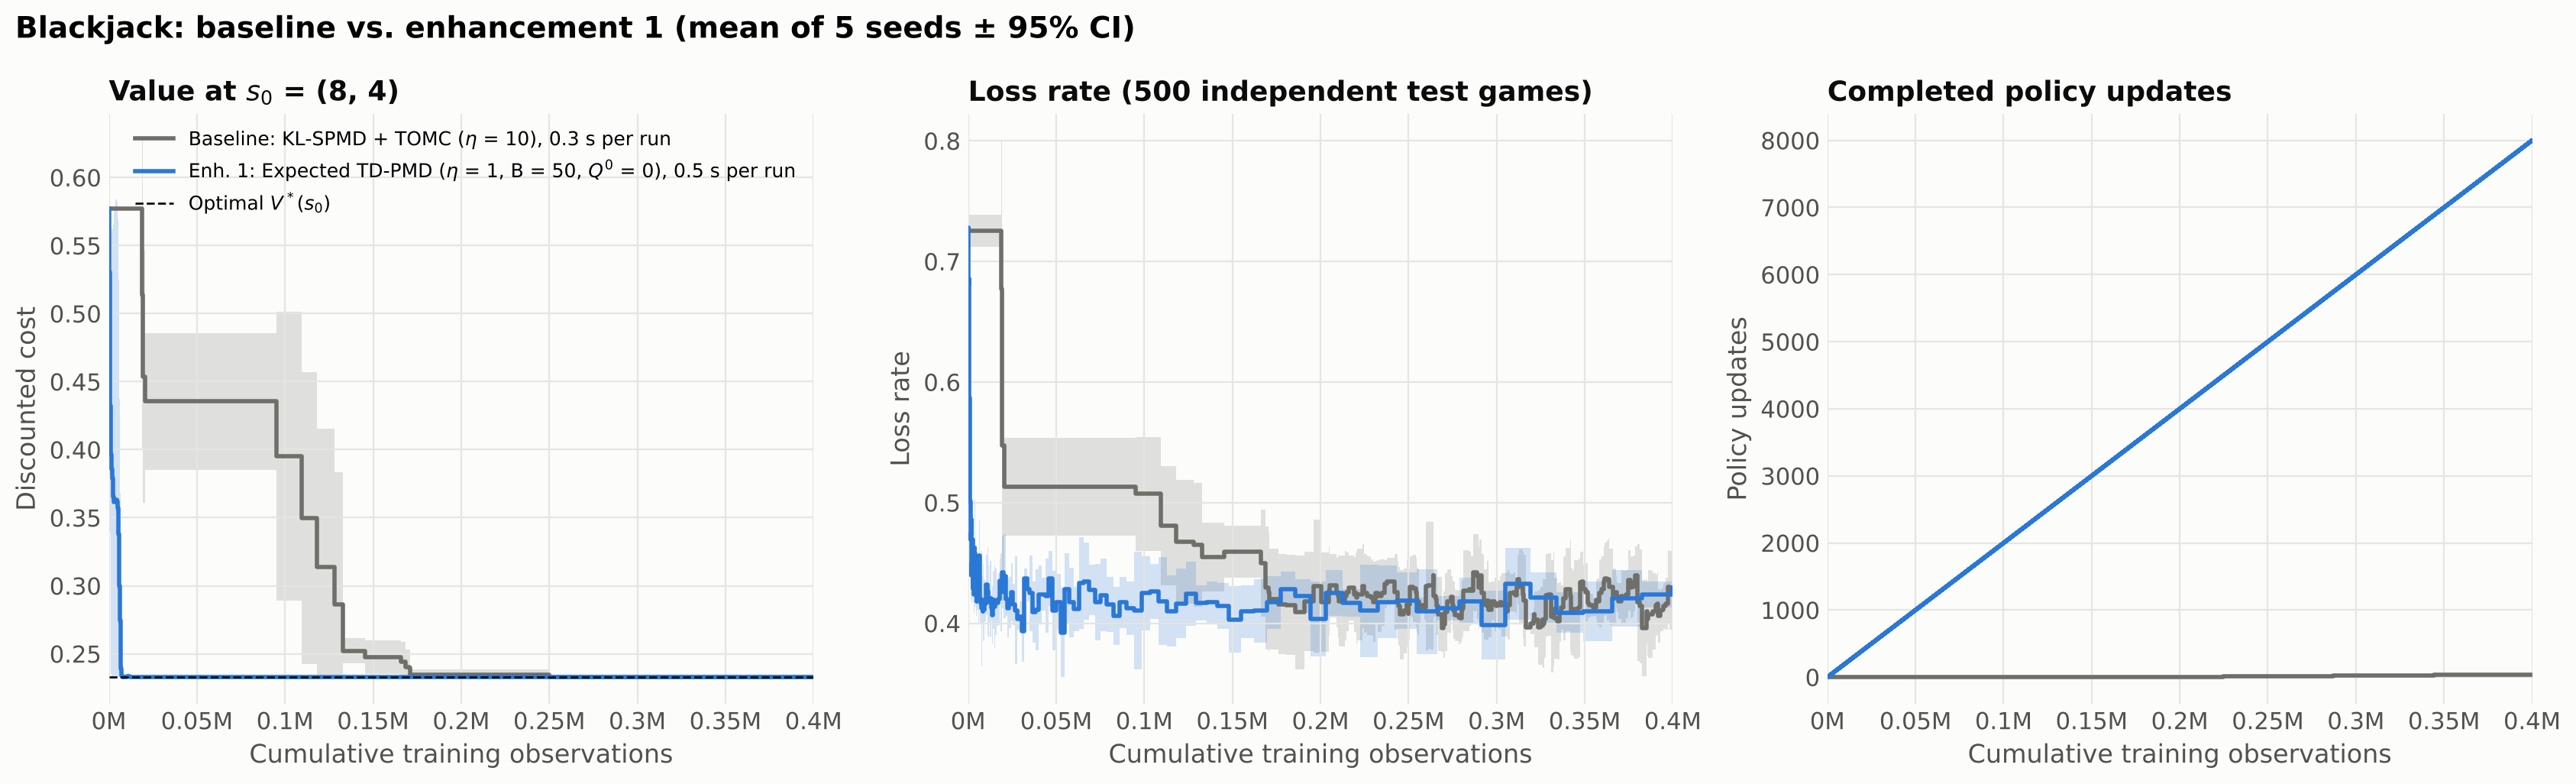

In [11]:
def apply_plot_style(large=False):
    plt.rcdefaults()
    plt.rcParams.update({
        "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "savefig.facecolor": BACKGROUND,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.spines.left": False, "axes.spines.bottom": False,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
        "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "legend.frameon": False, "font.family": "DejaVu Sans",
        "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10.5,
    })
    if large:
        plt.rcParams.update({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16,
                             "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14})


def plot_band(ax, points, curves, color, line_label, band_label=None, linewidth=2.0, lower=None):
    """Staircase mean across seeds with a shaded 95% confidence band.

    lower: a hard bound of the metric (V* for an exact value). The symmetric t-interval can
    cross it when seeds disagree (some converged, some not); the band is cut there.
    """
    mean, half_width = mean_ci(curves)
    low = mean - half_width if lower is None else np.maximum(mean - half_width, lower)
    ax.fill_between(points, low, mean + half_width, step="post",
                    color=color, alpha=0.2, linewidth=0, label=band_label)
    ax.step(points, mean, where="post", color=color, linewidth=linewidth, label=line_label)
    return mean, half_width


def save_figure(fig, name):
    FIGURES.mkdir(exist_ok=True)
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{suffix}", dpi=200, bbox_inches="tight")


def use_update_axis(ax):
    """Plain linear axis with whole-number ticks, as in the baseline."""
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))


millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
n_seeds = len(runs)
v_star = V_STAR[REPORT_STATE]
B_BEST = BEST["batch_size"]
CONFIG_TEXT = f"$\\eta$ = {BEST['eta']:g}, B = {B_BEST:,}, $Q^0$ = {BEST['initial_q']:g}"

enh_points = update_points(runs, SAMPLE_BUDGET)
enh_values = np.array([on_grid(run, enh_points, "values")[:, REPORT_STATE] for run in runs])
enh_losses = np.array([on_grid(run, enh_points, "loss_rate") for run in runs])
enh_update_points = np.arange(0, SAMPLE_BUDGET + 1, B_BEST)            # One update every B observations.
enh_updates = np.tile(enh_update_points // B_BEST, (n_seeds, 1))

ENH_NAME = f"Enh. 1: Expected TD-PMD ({CONFIG_TEXT})"
ENH_TIME = f"{ENH_SECONDS:.1f} s per run"
BASE_NAME = f"Baseline: KL-SPMD + TOMC ($\\eta$ = {BASE_ETA:g})"
BASE_TIME = f"{BASE_SECONDS:.1f} s per run"


# Each entry: (points, curves, color, legend label); baseline first, then the enhancement.
# The value labels carry each method's measured training time per full-budget run.
value_series = [(base_points, base_values, BASELINE_COLOR, f"{BASE_NAME}, {BASE_TIME}"),
                (enh_points, enh_values, ENH_COLOR, f"{ENH_NAME}, {ENH_TIME}")]
loss_series = [(base_points, base_losses, BASELINE_COLOR, BASE_NAME),
               (enh_points, enh_losses, ENH_COLOR, ENH_NAME)]
update_series = [(base_points, base_updates, BASELINE_COLOR, BASE_NAME),
                 (enh_update_points, enh_updates, ENH_COLOR, ENH_NAME)]
TITLE_START = "Blackjack: baseline vs. enhancement 1"

# Overview: three panels side by side, both methods in every panel.
apply_plot_style()
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, series, lower in zip(axes, (value_series, loss_series, update_series), (v_star, None, None)):
    for points, curves, color, label in series:
        plot_band(ax, points, curves, color, label, lower=lower)
axes[0].axhline(v_star, color=INK, linewidth=1, linestyle="--", label="Optimal $V^*(s_0)$")
axes[0].set(title=f"Value at $s_0$ = {REPORT_LABEL}", ylabel="Discounted cost")
axes[1].set(title=f"Loss rate ({TEST_GAMES} independent test games)", ylabel="Loss rate")
axes[2].set(title="Completed policy updates", ylabel="Policy updates")
use_update_axis(axes[2])
for ax in axes:
    ax.set(xlabel="Cumulative training observations", xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle(f"{TITLE_START} (mean of {n_seeds} seeds ± 95% CI)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh1_results")
plt.show()

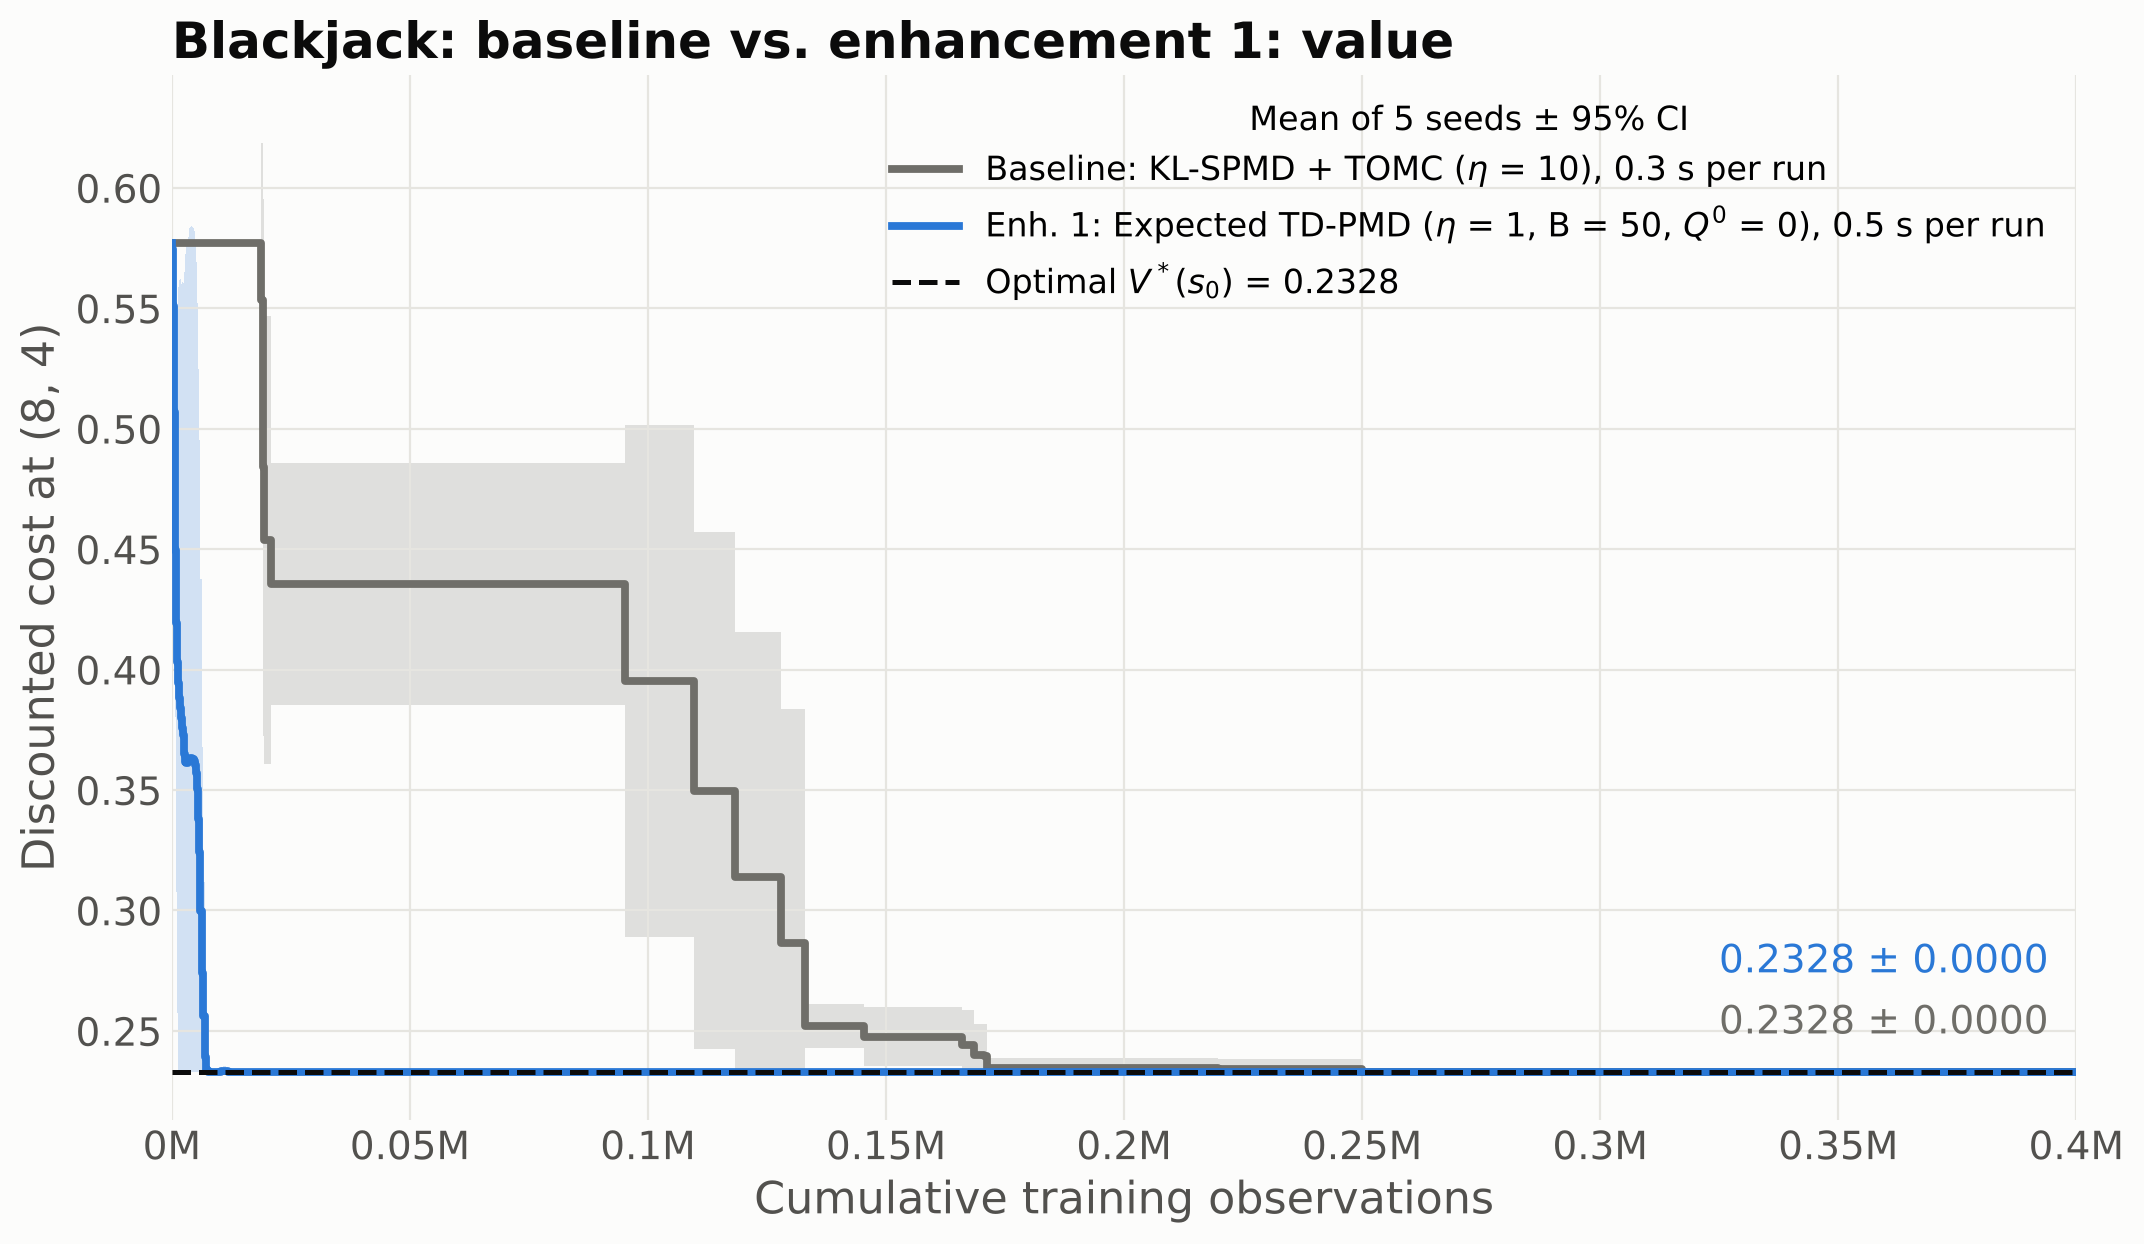

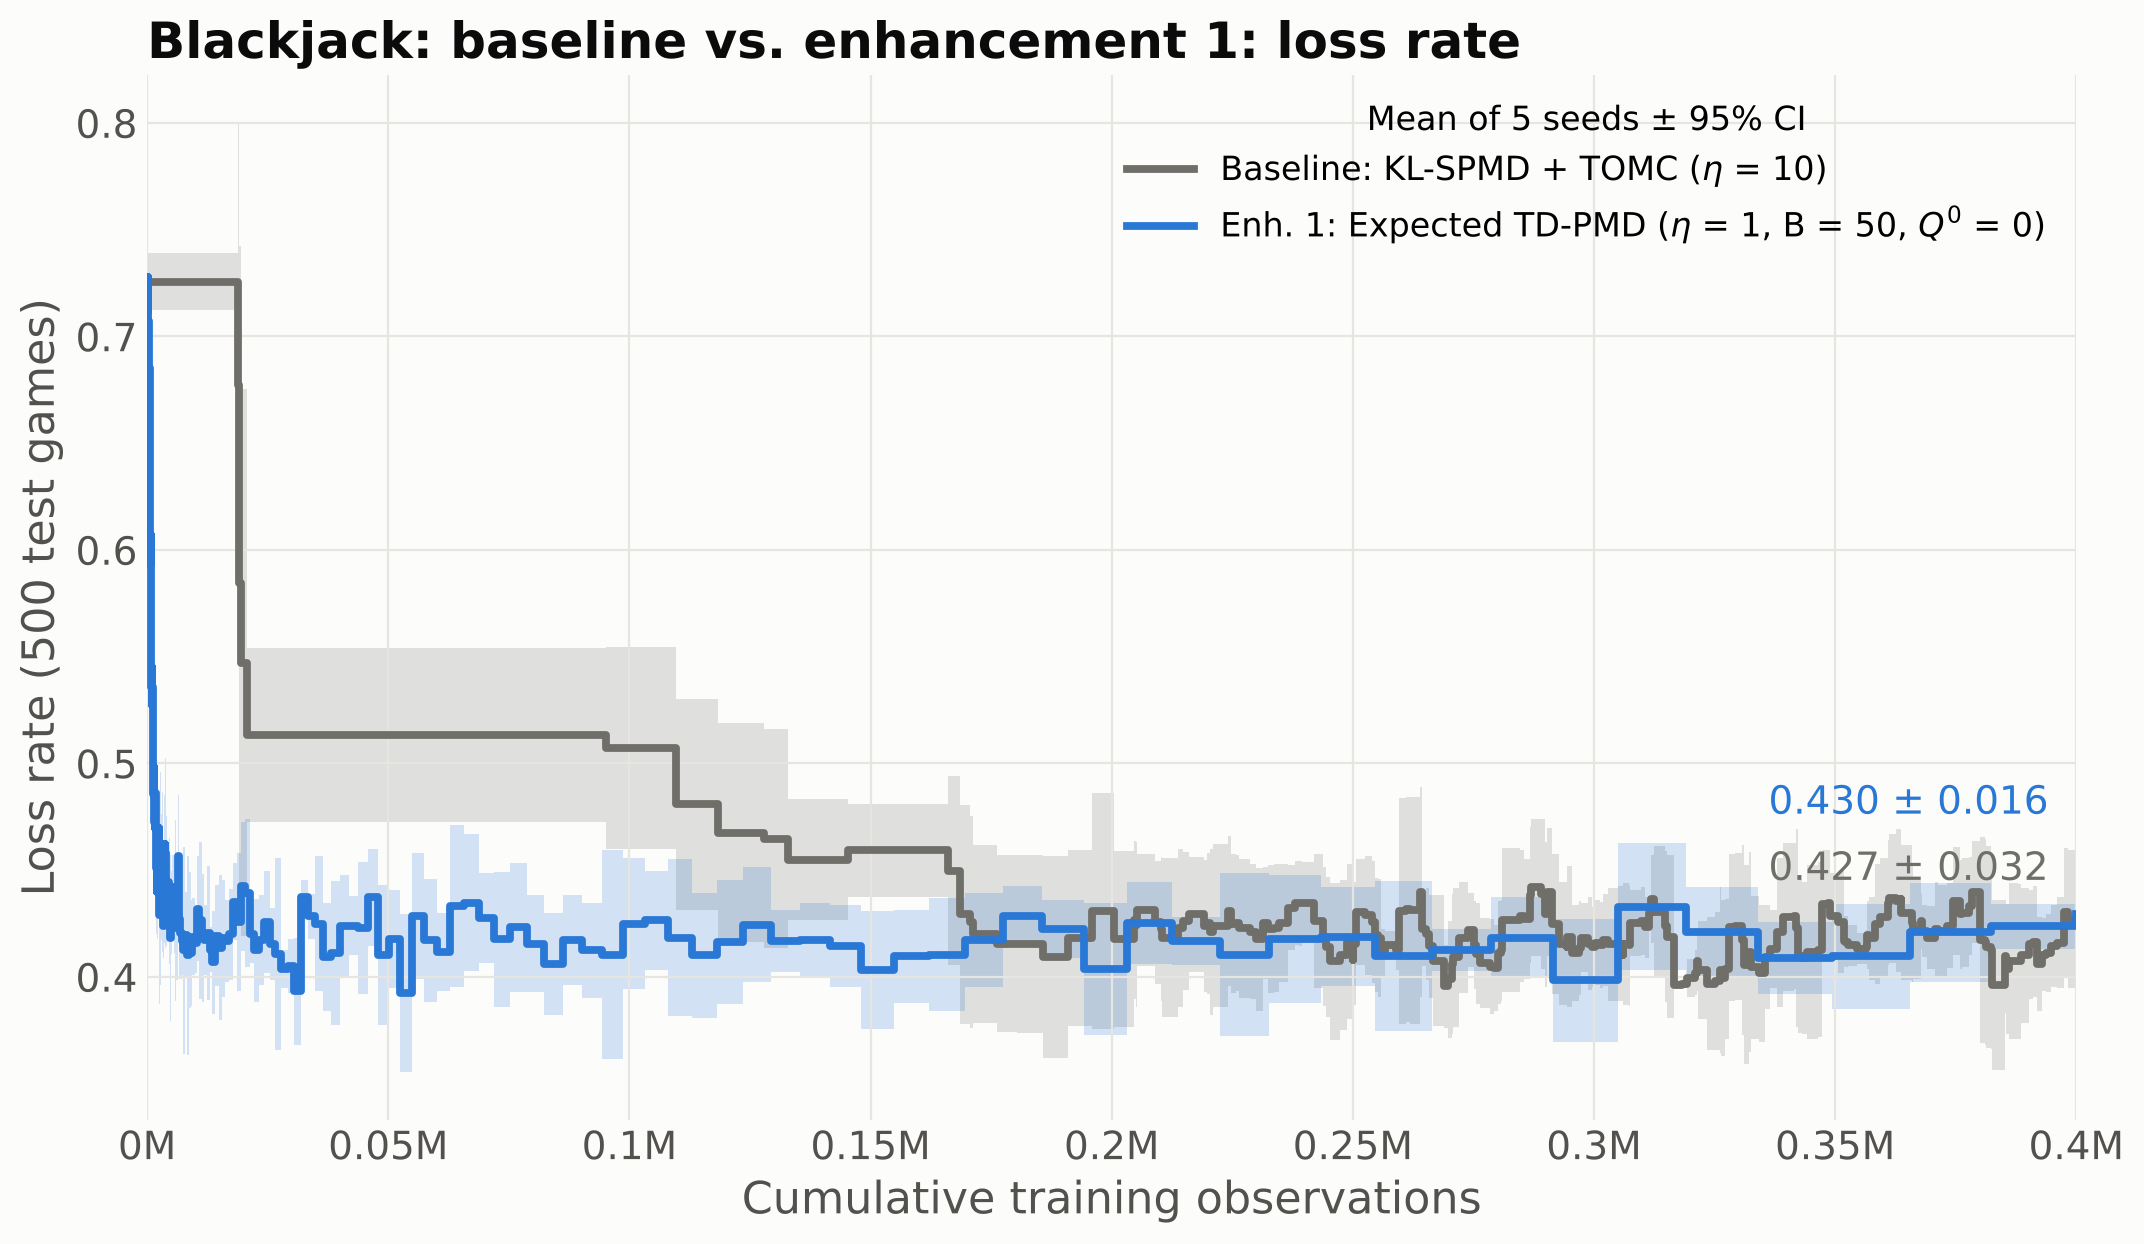

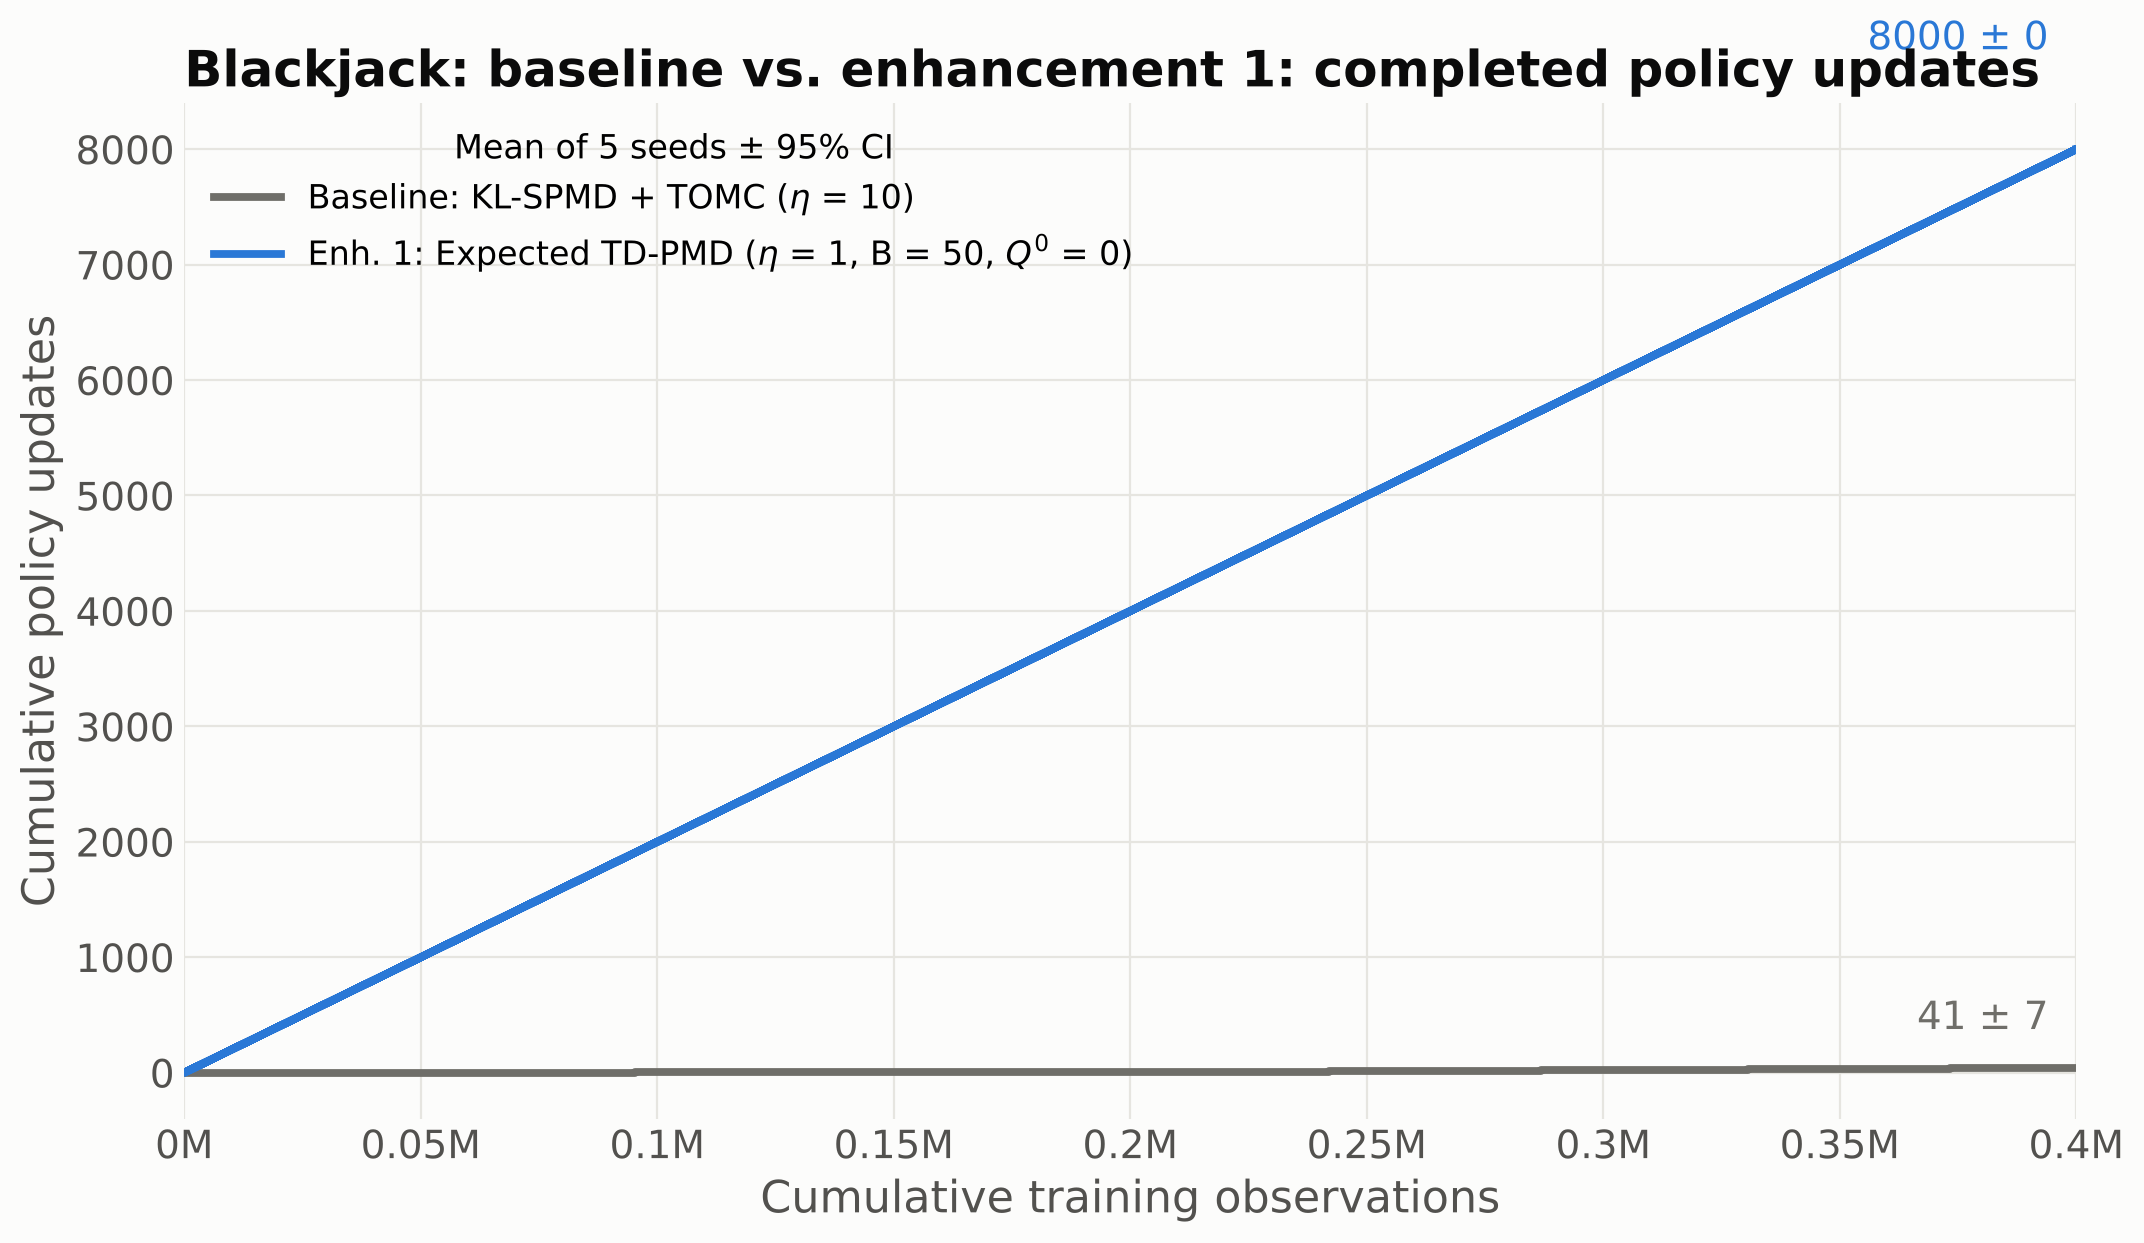

In [12]:
# Large slide figures, one per metric (same size and fonts as the baseline slide figures).
def slide_figure(series, title, ylabel, name, reference=None, reference_label=None,
                 value_format="{:.4f}", update_axis=False, lower=None):
    """series: list of (points, curves, color, legend label), drawn with mean ± 95% CI."""
    apply_plot_style(large=True)
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for index, (points, curves, color, label) in enumerate(series):
        mean, half_width = plot_band(ax, points, curves, color, label, linewidth=2.8, lower=lower)
        # End labels are stacked so two curves ending at the same height stay readable.
        ax.annotate(f"{value_format.format(mean[-1])} ± {value_format.format(half_width[-1])}",
                    (points[-1], mean[-1]), xytext=(-10, 14 + 22 * index), textcoords="offset points",
                    ha="right", color=color, fontsize=14)
    if reference is not None:
        ax.axhline(reference, color=INK, linewidth=1.8, linestyle="--", label=reference_label)
    ax.set(title=title, xlabel="Cumulative training observations", ylabel=ylabel,
           xlim=(0, SAMPLE_BUDGET))
    ax.xaxis.set_major_formatter(millions)
    if update_axis:
        use_update_axis(ax)
    # The legend notes once that lines are means and bands are 95% confidence intervals.
    ax.legend(loc="best", fontsize=12, title=f"Mean of {n_seeds} seeds ± 95% CI", title_fontsize=12)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()


slide_figure(value_series, f"{TITLE_START}: value", f"Discounted cost at {REPORT_LABEL}",
             "blackjack_enh1_value", reference=v_star,
             reference_label=f"Optimal $V^*(s_0)$ = {v_star:.4f}", lower=v_star)
slide_figure(loss_series, f"{TITLE_START}: loss rate", f"Loss rate ({TEST_GAMES} test games)",
             "blackjack_enh1_loss_rate", value_format="{:.3f}")
slide_figure(update_series, f"{TITLE_START}: completed policy updates", "Cumulative policy updates",
             "blackjack_enh1_updates", value_format="{:.0f}", update_axis=True)

## 10b. Summary figure (2 x 2): value, estimate, loss rate, observations

1. Exact $V^{\pi_k}(s_0)$ against cumulative observations (band cut at $V^*$).
2. Sampled estimate $\widehat V_k(s_0)=\sum_a\pi_k(a\mid s_0)\widehat Q_k(s_0,a)$ against policy
   iteration $k$: the baseline's Monte Carlo estimate, and the critic $Q^k$ for E1.
3. Loss rate in 500 independent test games against cumulative observations, with the
   optimal policy's exact loss probability.
4. Cumulative observations against policy iteration $k$.
Mean of five seeds with 95% CIs; end labels give the final mean ± half-width. Baseline
iteration curves use the iterations completed by every seed. E1 runs 8,000 iterations and
the baseline about 40, so panels 2 and 4 use a logarithmic iteration axis by default.

Optimal policy: exact loss probability = 0.4181


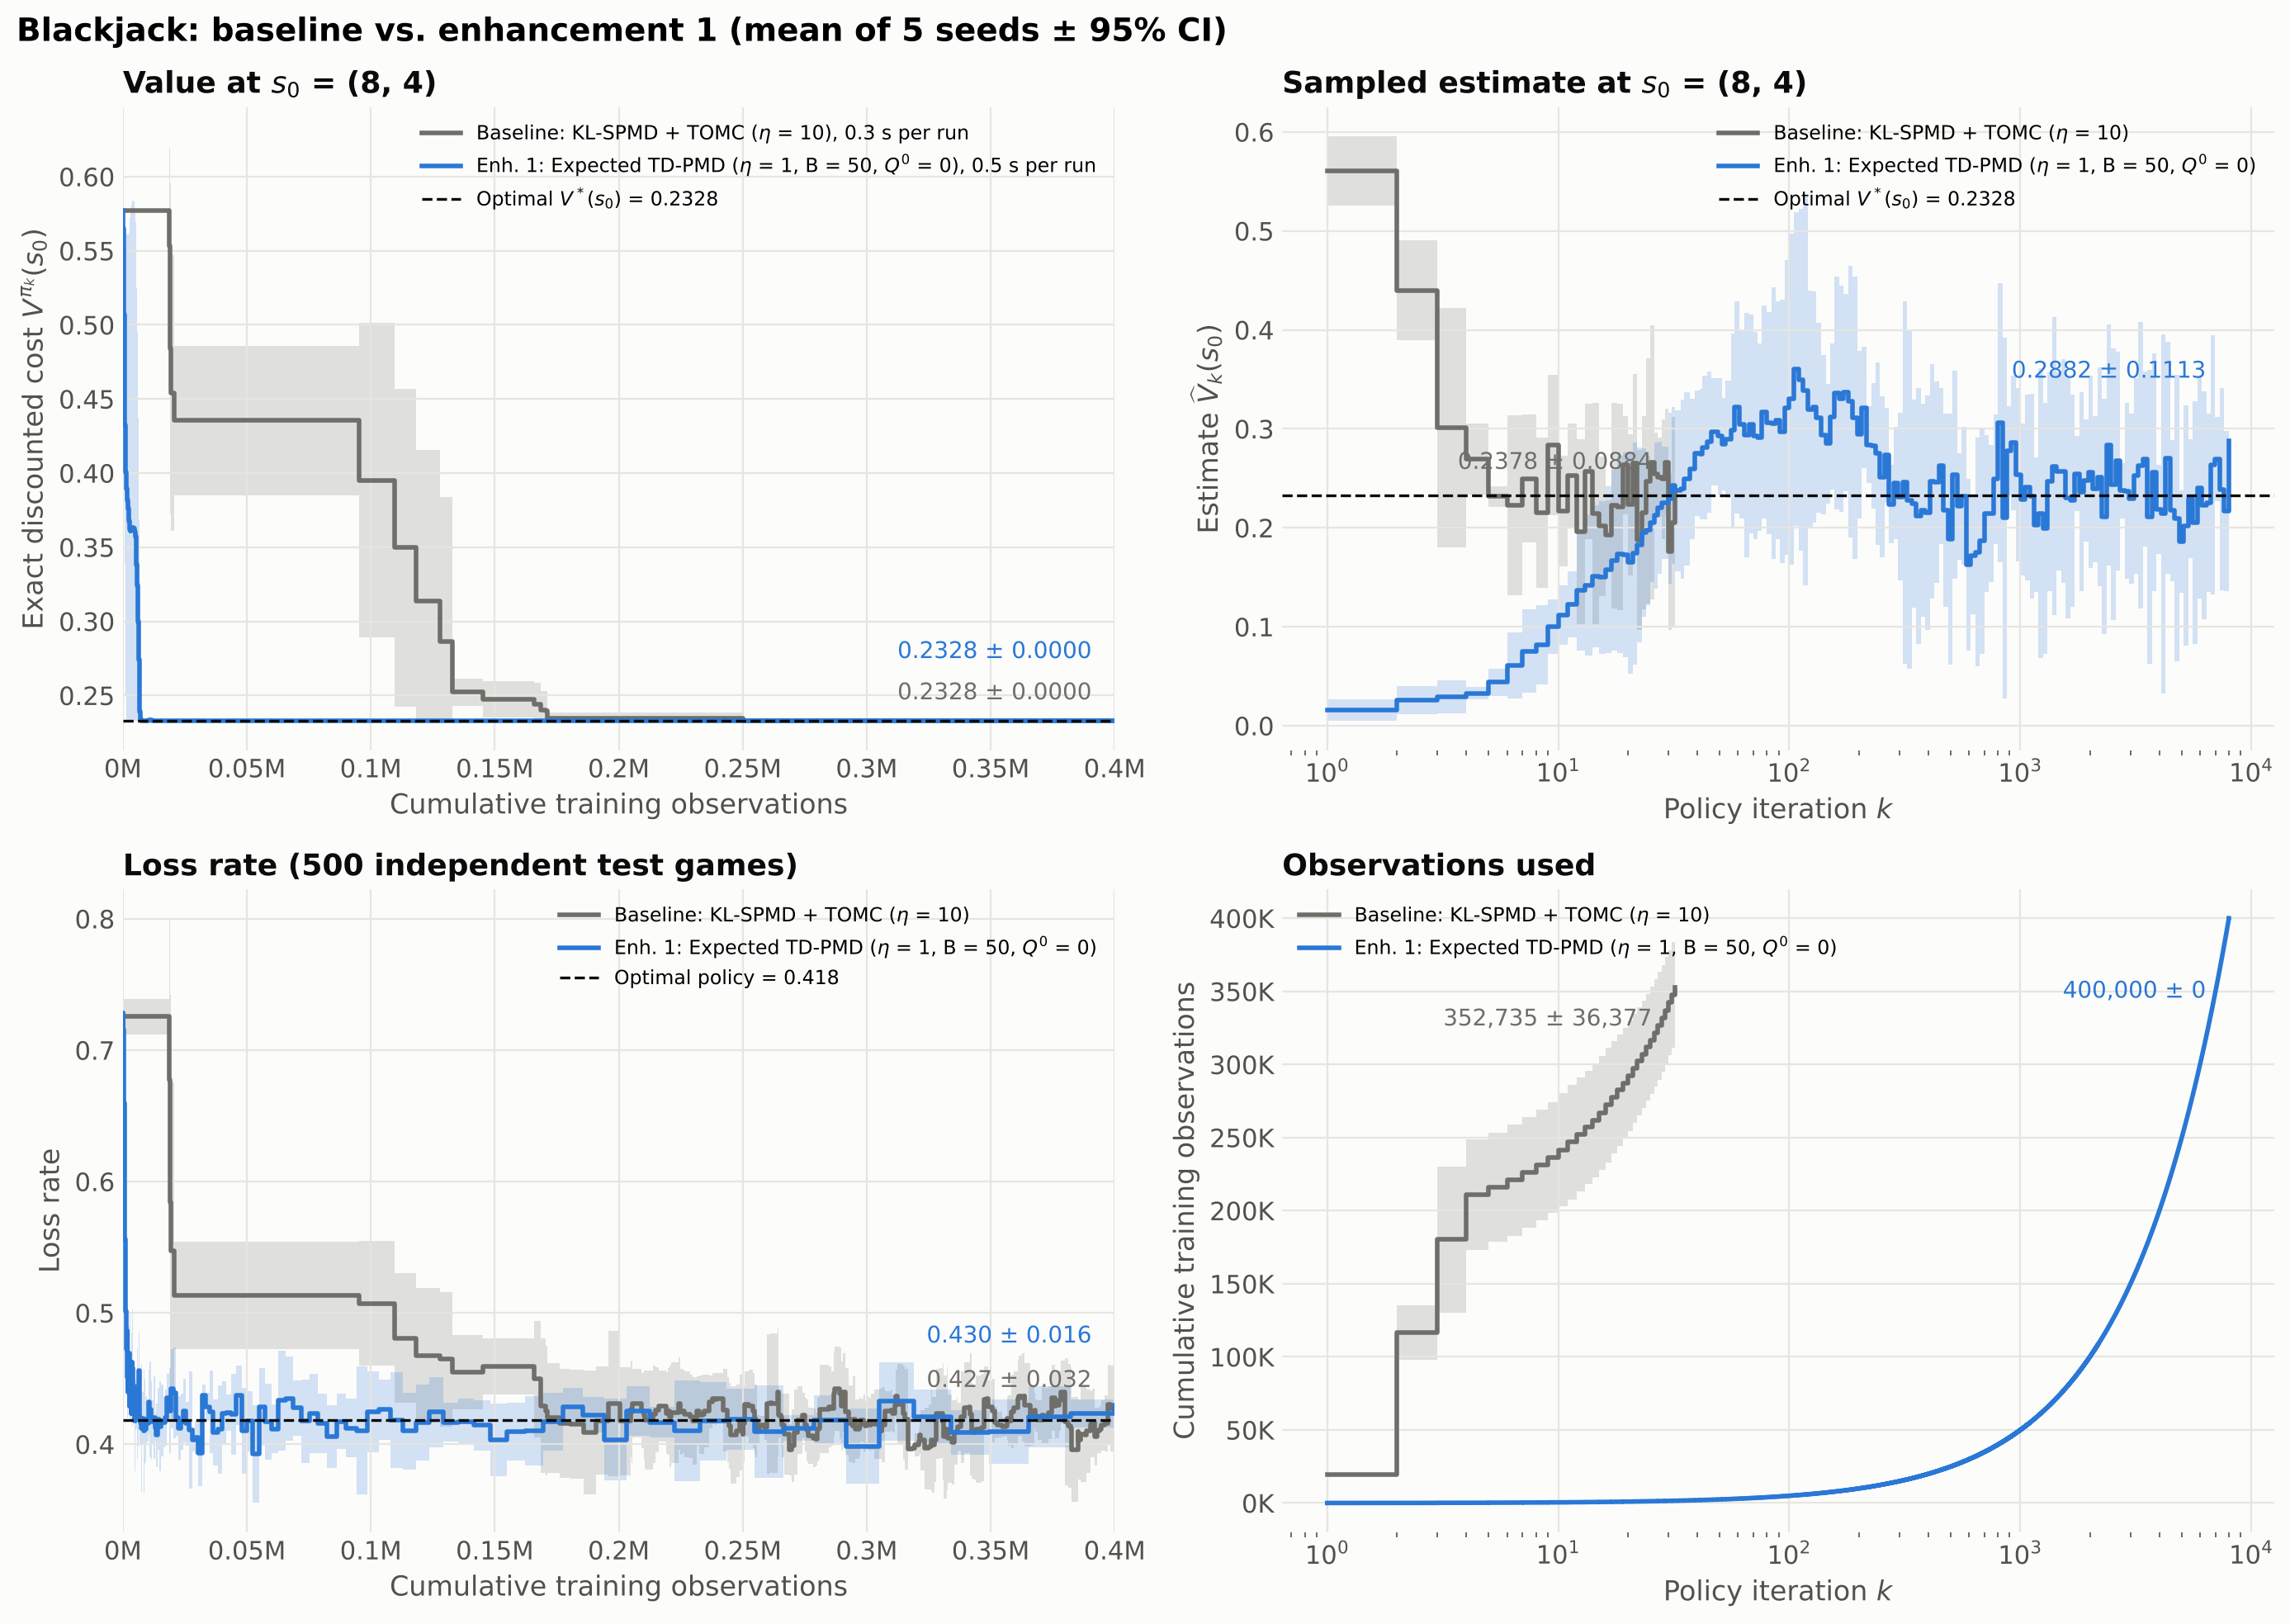

In [13]:
LOG_ITERATION_AXIS = True                 # Set False for a linear iteration axis in panels 2 and 4.


def exact_loss_probability(policy):
    """Exact probability that a freshly dealt hand is lost under `policy` (undiscounted)."""
    loss_now = np.zeros((N_STATES, N_ACTIONS))           # Loss on this action: lower total or bust.
    for dealer_card in DEALER_CARDS:
        dealer = dealer_final_distribution(dealer_card)
        for player_sum in PLAYER_SUMS:
            s = state2ID(player_sum, dealer_card)
            loss_now[s, STICK] = sum(prob for total, prob in dealer.items()
                                     if player_sum < total <= BUST_LIMIT)
            loss_now[s, HIT] = sum(player_sum + card > BUST_LIMIT for card in CARD_VALUES) / len(CARD_VALUES)
    P_pi = np.einsum("sa,sat->st", policy, P_exact)
    loss = np.linalg.solve(np.eye(N_STATES) - P_pi, np.sum(policy * loss_now, axis=1))
    start = np.zeros(N_STATES)                            # Deal: two player cards, one dealer card.
    for c1 in CARD_VALUES:
        for c2 in CARD_VALUES:
            for dealer_card in CARD_VALUES:
                start[state2ID(c1 + c2, dealer_card)] += 1 / len(CARD_VALUES) ** 3
    return float(start @ loss)


OPTIMAL_POLICY = np.eye(N_ACTIONS)[OPTIMAL_ACTIONS]
OPTIMAL_LOSS = exact_loss_probability(OPTIMAL_POLICY)
print(f"Optimal policy: exact loss probability = {OPTIMAL_LOSS:.4f}")


def common_prefix(arrays):
    """Stack per-seed arrays over the iterations every seed completed."""
    n = min(len(a) for a in arrays)
    return np.array([np.asarray(a, dtype=float)[:n] for a in arrays])


def label_end(ax, x, mean, half_width, color, index, value_format, below=False):
    """Final mean ± half-width next to the end of a curve; stacked so labels do not overlap."""
    offset = -(14 + 18 * index) if below else 12 + 18 * index
    ax.annotate(f"{value_format.format(mean[-1])} ± {value_format.format(half_width[-1])}",
                (x[-1], mean[-1]), xytext=(-10, offset), textcoords="offset points",
                ha="right", va="center", color=color, fontsize=10)


# Panel 2: sampled estimate by iteration. Baseline: estimate of iteration k (k = 1, 2, ...).
# E1: critic estimate at its checkpoints (iteration 0 is the constant Q^0, left out).
base_estimates = common_prefix([run["estimate"] for run in baseline_runs])
base_est_iters = np.arange(1, base_estimates.shape[1] + 1)
enh_iters = runs[0]["updates"]
assert all(np.array_equal(run["updates"], enh_iters) for run in runs)
keep_iters = enh_iters >= 1
enh_est_iters = enh_iters[keep_iters]
enh_estimates = np.array([run["critic_estimate"][keep_iters] for run in runs])

# Panel 4: cumulative observations after k completed iterations (k >= 1).
base_obs = common_prefix([run["samples"][1:] for run in baseline_runs])
base_obs_iters = np.arange(1, base_obs.shape[1] + 1)
enh_obs_iters = np.arange(1, SAMPLE_BUDGET // B_BEST + 1)
enh_obs = np.tile(enh_obs_iters * B_BEST, (n_seeds, 1))

panels = [
    (value_series, v_star, "{:.4f}", f"Value at $s_0$ = {REPORT_LABEL}",
     "Cumulative training observations", "Exact discounted cost $V^{\\pi_k}(s_0)$"),
    ([(base_est_iters, base_estimates, BASELINE_COLOR, BASE_NAME),
      (enh_est_iters, enh_estimates, ENH_COLOR, ENH_NAME)], None, "{:.4f}",
     f"Sampled estimate at $s_0$ = {REPORT_LABEL}", "Policy iteration $k$",
     "Estimate $\\widehat V_k(s_0)$"),
    (loss_series, None, "{:.3f}", f"Loss rate ({TEST_GAMES} independent test games)",
     "Cumulative training observations", "Loss rate"),
    ([(base_obs_iters, base_obs, BASELINE_COLOR, BASE_NAME),
      (enh_obs_iters, enh_obs, ENH_COLOR, ENH_NAME)], None, "{:,.0f}",
     "Observations used", "Policy iteration $k$", "Cumulative training observations"),
]

apply_plot_style()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for index, (ax, (series, lower, value_format, title, xlabel, ylabel)) in enumerate(zip(axes.flat, panels)):
    for line, (points, curves, color, label) in enumerate(series):
        mean, half_width = plot_band(ax, points, curves, color, label, lower=lower)
        label_end(ax, points, mean, half_width, color, line, value_format, below=index == 3)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    if index in (0, 2):
        ax.set_xlim(0, SAMPLE_BUDGET)
        ax.xaxis.set_major_formatter(millions)
    elif LOG_ITERATION_AXIS:
        ax.set_xscale("log")
for ax in (axes[0, 0], axes[0, 1]):
    ax.axhline(v_star, color=INK, linewidth=1.2, linestyle="--", label=f"Optimal $V^*(s_0)$ = {v_star:.4f}")
axes[1, 0].axhline(OPTIMAL_LOSS, color=INK, linewidth=1.2, linestyle="--",
                   label=f"Optimal policy = {OPTIMAL_LOSS:.3f}")
axes[1, 1].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1e3:g}K"))
for ax in axes.flat:
    ax.legend(loc="best", fontsize=8.5)
fig.suptitle(f"{TITLE_START} (mean of {n_seeds} seeds ± 95% CI)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh1_summary_2x2")
plt.show()

## 11. Tuning summary

One panel per critic initialization $Q^0$; each cell is the exact gap at (8, 4) after
20,000 observations (log color scale, darker is worse). The winner is outlined.
The baseline has no counterpart here: it tunes only eta.

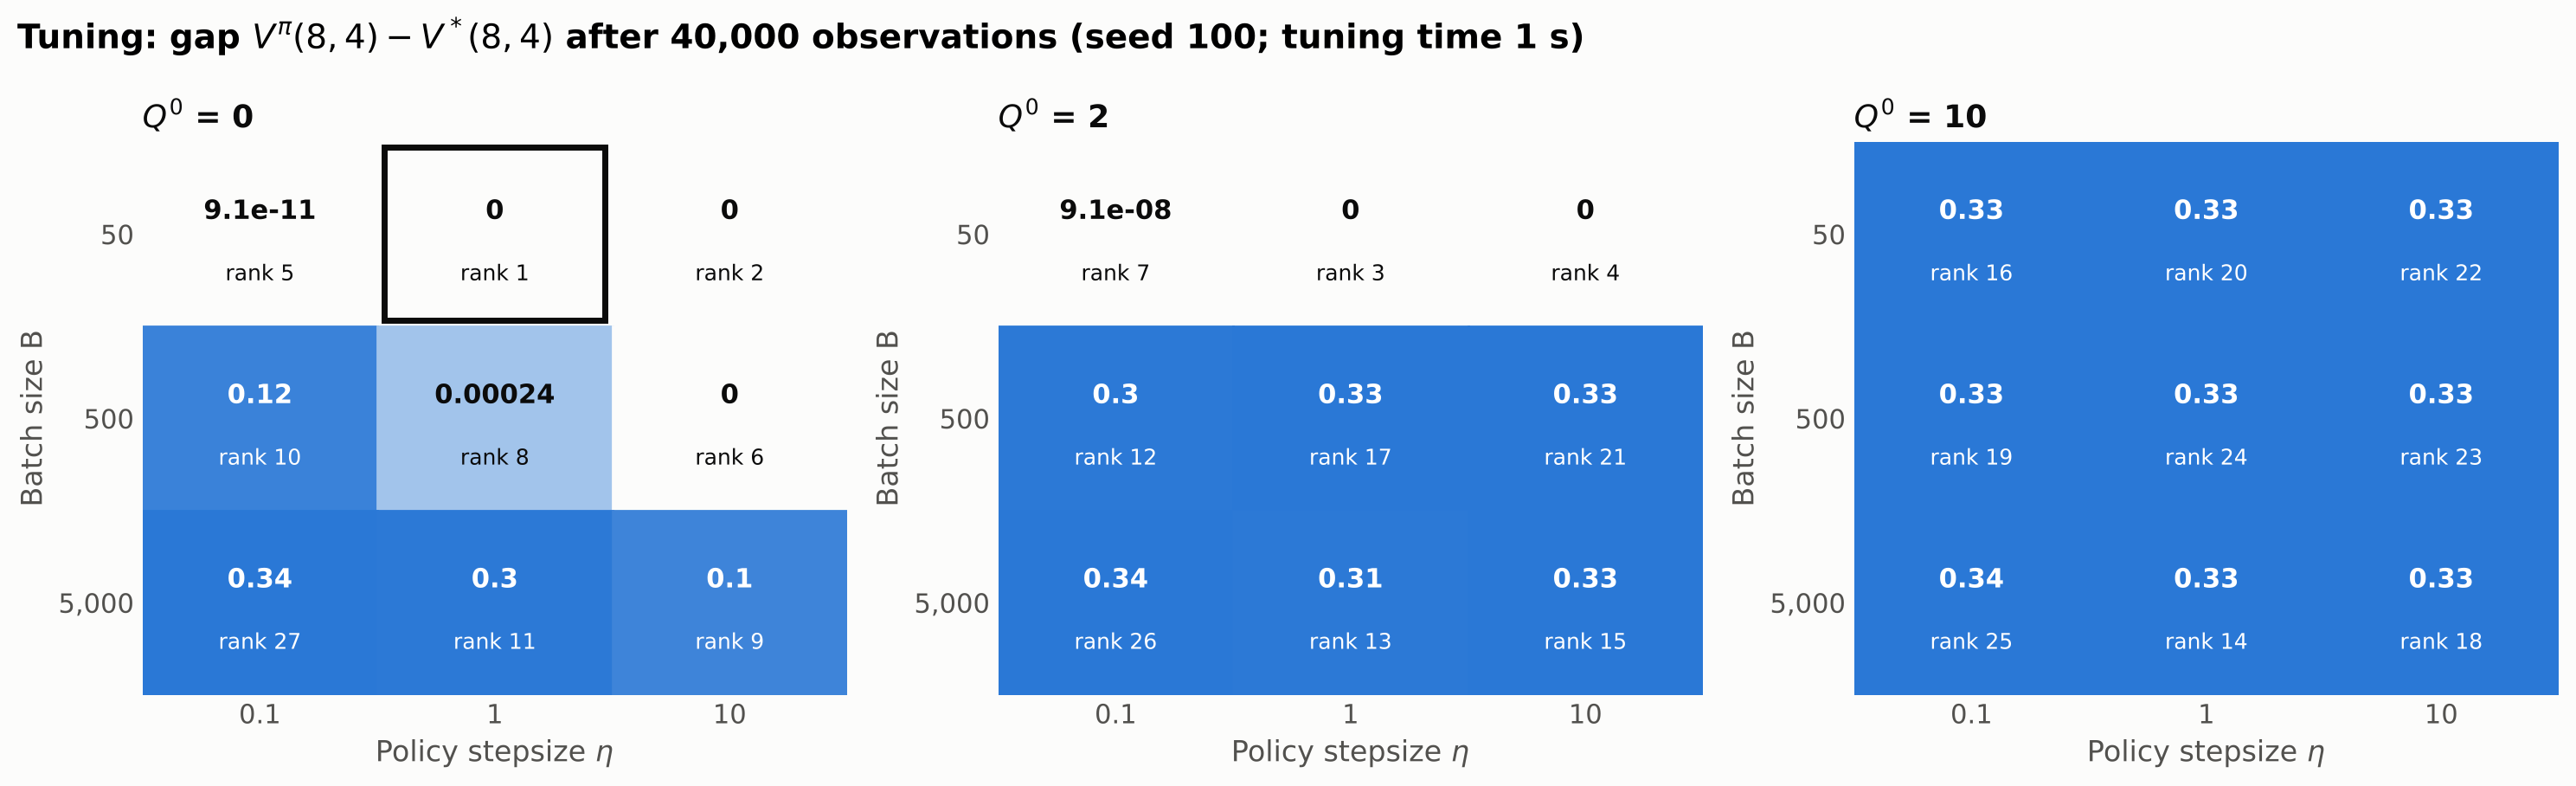

In [14]:
apply_plot_style()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
cmap = LinearSegmentedColormap.from_list("enh", [BACKGROUND, ENH_COLOR])
floor = 1e-6
gaps = np.maximum(tuning["gap_at_reference"].to_numpy(), floor)
norm = LogNorm(vmin=gaps.min(), vmax=max(gaps.max(), 10 * gaps.min()))
for ax, initial_q in zip(axes, INITIAL_Q_CANDIDATES):
    for i, batch_size in enumerate(BATCH_CANDIDATES):
        for j, eta in enumerate(ETA_CANDIDATES):
            row = tuning[(tuning["Q0"] == initial_q) & (tuning["B"] == batch_size)
                         & (tuning["eta"] == eta)].iloc[0]
            gap = max(row["gap_at_reference"], floor)
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, color=cmap(norm(gap))))
            text_color = "white" if norm(gap) > 0.6 else INK
            ax.text(j, i - 0.12, f"{row['gap_at_reference']:.2g}", ha="center", va="center",
                    fontsize=11, color=text_color, fontweight="bold")
            ax.text(j, i + 0.22, f"rank {int(row['rank'])}", ha="center", va="center",
                    fontsize=9, color=text_color)
            if row["rank"] == 1:
                ax.add_patch(Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False,
                                       edgecolor=INK, linewidth=2.5))
    ax.set(xlim=(-0.5, 2.5), ylim=(2.5, -0.5), title=f"$Q^0$ = {initial_q:g}",
           xticks=range(3), xticklabels=[f"{eta:g}" for eta in ETA_CANDIDATES],
           yticks=range(3), yticklabels=[f"{b:,}" for b in BATCH_CANDIDATES],
           xlabel="Policy stepsize $\\eta$", ylabel="Batch size B")
    ax.grid(False)
fig.suptitle(f"Tuning: gap $V^{{\\pi}}{REPORT_LABEL} - V^*{REPORT_LABEL}$ after "
             f"{TUNING_BUDGET:,} observations (seed {TUNING_SEED}; tuning time {tuning_seconds:.0f} s)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "blackjack_enh1_tuning")
plt.show()

## 12. Comparison table at the full budget

In [15]:
comparison = pd.DataFrame([
    {"method": "Baseline: KL-SPMD + TOMC", "settings": f"eta = {BASE_ETA:g}",
     **{key: format_mean_ci([fn(run) for run in baseline_runs], digits) for key, fn, digits in (
         ("gap_at_reference", lambda r: on_grid(r, budget, "values")[0, REPORT_STATE] - v_star, 4),
         ("mean_gap_all_states", lambda r: np.mean(on_grid(r, budget, "values")[0] - V_STAR), 4),
         ("loss_rate", lambda r: on_grid(r, budget, "loss_rate")[0], 3),
         ("policy_updates", lambda r: on_grid(r, budget, "updates")[0], 1),
         ("seconds_per_run", lambda r: r["seconds"], 1))}},
    {"method": "Enh. 1: Expected TD-PMD",
     "settings": f"eta = {BEST['eta']:g}, B = {B_BEST}, Q0 = {BEST['initial_q']:g}",
     **{key: format_mean_ci(summary[column], digits) for key, column, digits in (
         ("gap_at_reference", "gap_at_reference", 4),
         ("mean_gap_all_states", "mean_gap_all_states", 4),
         ("loss_rate", "loss_rate", 3),
         ("policy_updates", "policy_updates", 1),
         ("seconds_per_run", "train_seconds", 1))}},
])
print(f"Both methods at {SAMPLE_BUDGET:,} training observations (mean ± 95% CI over 5 seeds):")
print(comparison.to_string(index=False))
print(f"Tuning time, reported separately: enhancement (27 configurations) {tuning_seconds:.1f} s; "
      f"baseline ({len(BASELINE_ETA_CANDIDATES)} stepsizes) {baseline_tuning_seconds:.1f} s.")

Both methods at 400,000 training observations (mean ± 95% CI over 5 seeds):
                  method                settings gap_at_reference mean_gap_all_states     loss_rate policy_updates seconds_per_run
Baseline: KL-SPMD + TOMC                eta = 10  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.427 ± 0.032     40.8 ± 7.3       0.3 ± 0.0
 Enh. 1: Expected TD-PMD eta = 1, B = 50, Q0 = 0  0.0000 ± 0.0000    -0.0000 ± 0.0000 0.430 ± 0.016   8000.0 ± 0.0       0.5 ± 0.1
Tuning time, reported separately: enhancement (27 configurations) 1.2 s; baseline (3 stepsizes) 0.1 s.


## 13. Learned policy of the first seed

P(HIT) of the final target policy next to the optimal action.

In [16]:
final = runs[0]["final_policy"]
policy_table = pd.DataFrame(
    [[f"{final[state2ID(p, d), HIT]:.2f} ({'SH'[OPTIMAL_ACTIONS[state2ID(p, d)]]})"
      for d in DEALER_CARDS] for p in PLAYER_SUMS],
    index=[f"sum {p}" for p in PLAYER_SUMS], columns=[f"dealer {d}" for d in DEALER_CARDS])
print(f"Seed {runs[0]['seed']}: final P(HIT), optimal action in brackets")
print(policy_table.to_string())

Seed 0: final P(HIT), optimal action in brackets
        dealer 2  dealer 3  dealer 4  dealer 5
sum 4   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 5   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 6   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 7   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 8   1.00 (H)  1.00 (H)  1.00 (H)  1.00 (H)
sum 9   0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
sum 10  0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
sum 11  0.00 (S)  0.00 (S)  0.00 (S)  0.00 (S)
